# APM_50441_EP - Machine Learning 2 - Lab 1: Risk estimation, weights, hyperparameters and time series

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC1/APM_50441_EP_Lab_1_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This lab illustrates the first lecture (*Setting, Risk Estimation... and Time Series*). Its goals are:
- to estimate the risk of a predictor and to measure the uncertainty of this estimation (hold-out, cross validation, comparison of two models, selection rules),
- to take into account a difference between the training and the real-world proportions, and a cost depending on the prediction (weights, Bayes rule),
- to compare hyperparameter search strategies with a fixed budget, and to see how much the selection itself can be overfitted,
- to validate a forecast correctly when the data are a time series.

The optional *To go further* part, after the core, can be skipped at first.

We use `Python` with `scikit-learn`, `polars` and `seaborn`.

**Working environment.** Colab is the simplest option: open the notebook of this lab from the course repository (*Open in Colab* link) and run it. To work on your own computer, download the lab folder (the notebook and its files) or clone the course repository, and open the notebook in an IDE that runs Jupyter notebooks (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). Create a Python environment once with [`uv`](https://docs.astral.sh/uv/): `uv venv`, activate it (`source .venv/bin/activate`, or `.venv\Scripts\activate` on Windows) and `uv pip install jupyter`, or build the whole course environment with `uv sync` in `PC/env`; then select this environment as the kernel of the notebook. The installation cell below installs the packages of the lab into the Python running the notebook (Colab or your environment), and the data are read from the local files when they are present (otherwise they are downloaded).

**Use of AI.** AI assistants (e.g. the ones built into Colab or VS Code) are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

All the libraries of the core part are installed at once. On Colab, restart the session once after this installation; locally, restart the kernel if the installation upgraded a package that was already loaded.

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "scikit-learn==1.9.1" "polars==1.44.2" "seaborn==0.13.2" "fairlearn==0.14.0" "optuna==5.0.0" "statsmodels==0.15.0"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 6 packages in 59ms


We use the Credit Risk dataset prepared by IBM (a biased version of the classical German credit data), and `apm_credit.py`, a small module gathering the cost model that we build step by step in this lab, so that the next labs can simply import it. Each file is downloaded only if there is no local copy.

In [3]:
import os
import urllib.request

# each file is downloaded only if there is no local copy
CSV_URL = "https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv"
APM_CREDIT_URL = "https://raw.githubusercontent.com/APM-50441-EP/APM_50441_EP-2026-2027/main/common/apm_credit.py"  # course repository
for url in [CSV_URL, APM_CREDIT_URL]:
  filename = url.split('/')[-1]
  if not os.path.exists(filename):
    urllib.request.urlretrieve(url, filename)

The dataset, the training/test split and two pipelines (a logistic regression and a nearest neighbors classifier) are given: this was the content of the first labs of the previous course.

In [4]:
import numpy as np
import polars as pl
import polars.selectors as cs
import seaborn.objects as so
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2, user_api='openmp')  # on such small datasets, many threads are slower than a few (Colab has 2 cores)

german_credit = pl.read_csv("german_credit_data_biased_training.csv")
X = german_credit.drop('Risk')
y = german_credit['Risk']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

categorical_features = X.select(cs.string()).columns
numerical_features = X.select(cs.numeric()).columns
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
    ('num', StandardScaler(), numerical_features)])

def make_pipeline(classifier):
  return Pipeline(steps=[('preprocessor', clone(preprocessor)), ('classifier', classifier)]).set_output(transform="polars")

pipeline_log = make_pipeline(LogisticRegression(max_iter=1000))
pipeline_nn = make_pipeline(KNeighborsClassifier(n_neighbors=15))
german_credit.shape, y_train.value_counts(normalize=True).sort('Risk')

((5000, 21),
 shape: (2, 2)
 ┌─────────┬────────────┐
 │ Risk    ┆ proportion │
 │ ---     ┆ ---        │
 │ str     ┆ f64        │
 ╞═════════╪════════════╡
 │ No Risk ┆ 0.666      │
 │ Risk    ┆ 0.334      │
 └─────────┴────────────┘)

## 1. Risk estimation and model comparison

The *risk* of a predictor $f$ is its average loss on a new observation, $\mathcal{R}(f) = \mathbb{E}[\ell(Y, f(X))]$. It is unknown and must be estimated from data that have not been used to train $f$.

**Question** *Predict before you run.* For the $1$-nearest neighbor, the $15$-nearest neighbors and the logistic regression, what do you expect for the accuracy on the training set compared with the accuracy on the test set? Check it.

**Answer**

In [5]:
results = []
for name, pipeline in {'1-NN': make_pipeline(KNeighborsClassifier(n_neighbors=1)),
                       '15-NN': pipeline_nn, 'logistic': pipeline_log}.items():
  pipeline.fit(X_train, y_train)
  results.append({'model': name, 'training accuracy': pipeline.score(X_train, y_train),
                  'test accuracy': pipeline.score(X_test, y_test)})
pl.DataFrame(results).with_columns((pl.col('training accuracy') - pl.col('test accuracy')).alias('optimism'))

model,training accuracy,test accuracy,optimism
str,f64,f64,f64
"""1-NN""",1.0,0.739,0.261
"""15-NN""",0.8095,0.798,0.0115
"""logistic""",0.80275,0.8,0.00275


**Conclusion** The $1$-NN has a training accuracy of $1$ (each point is its own nearest neighbor) but a test accuracy of $0.739$: an optimism of $0.26$. The optimism is much smaller for the $15$-NN ($0.012$) and the logistic regression ($0.003$), which are less flexible. The training error is an optimistic estimate of the risk (PC1, Exercise 1), all the more so as the method can adapt to the training data.

---

A single test set gives a single, noisy, estimate. To see how noisy, we can repeat the *hold-out* procedure: split the training set into a training part and a validation part many times.

**Question** Estimate the accuracy of the logistic regression with $20$ random hold-out splits ($80\%$/$20\%$) of the training set, and with a $5$-fold cross validation repeated $4$ times (`StratifiedKFold(n_splits=5, shuffle=True, random_state=i)`). Compare the spread of the individual estimates, and of the averages.

**Answer**

In [6]:
from sklearn.model_selection import ShuffleSplit
holdout = cross_val_score(pipeline_log, X_train, y_train, cv=ShuffleSplit(n_splits=20, test_size=0.2, random_state=0))
cv_repeated = pl.concat([pl.DataFrame({'rep': i, 'fold': range(5),
                                       'score': cross_val_score(pipeline_log, X_train, y_train,
                                                                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=i))})
                         for i in range(4)])
print(f'hold-out: mean {holdout.mean():.4f}, sd {holdout.std(ddof=1):.4f}')
cv_repeated.group_by('rep').agg(pl.col('score').mean().alias('mean'), pl.col('score').std().alias('sd')).sort('rep')

hold-out: mean 0.7966, sd 0.0098


rep,mean,sd
i32,f64,f64
0,0.79625,0.017744
1,0.79725,0.005184
2,0.79725,0.010947
3,0.79775,0.016593


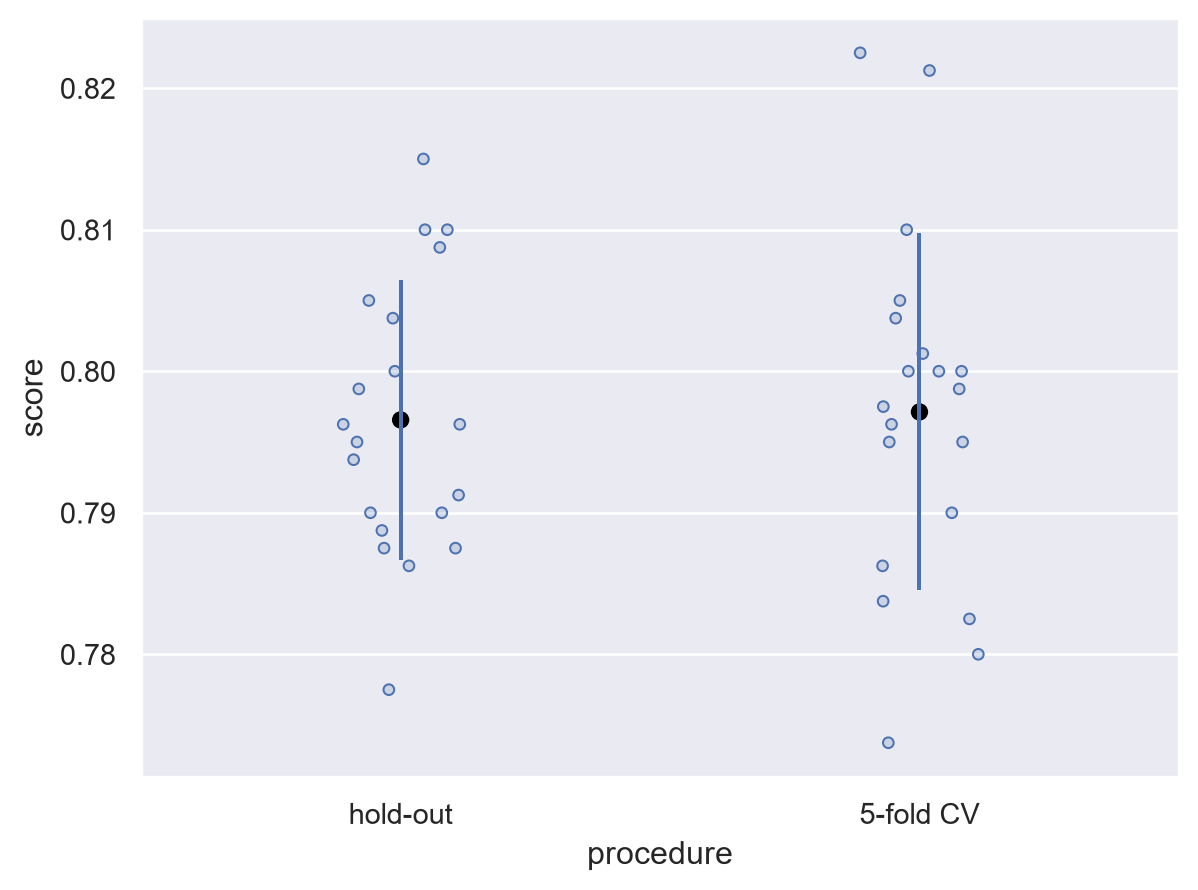

In [7]:
(so.Plot(pl.concat([pl.DataFrame({'procedure': 'hold-out', 'score': holdout}),
                    cv_repeated.select(pl.lit('5-fold CV').alias('procedure'), 'score')]), x='procedure', y='score')
 .add(so.Dots(), so.Jitter(.3))
 .add(so.Range(), so.Est(errorbar='sd'))
 .add(so.Dot(color='black'), so.Agg()))

**Conclusion** The $20$ hold-out estimates have a standard deviation of about $0.010$: a single hold-out split could give anything between about $0.78$ and $0.81$. The fold scores of the cross validation are as variable (standard deviations from $0.005$ to $0.018$ depending on the shuffle), but their averages are much more stable: from $0.796$ to $0.798$ for the $4$ repetitions. Averaging over the folds, and over repetitions, reduces the variance of the estimate.

---

The standard deviation of the fold scores describes the variability of the accuracy of *one* fitted model on *one* validation set; the standard error (the standard deviation divided by $\sqrt{V}$) describes the variability of their *mean*, under an independence assumption that does not hold (the training parts of the folds overlap).

**Question** Compare the logistic regression and the $15$-nearest neighbors on the *same* folds ($5$-fold CV repeated $4$ times). Compute the paired differences, and compare a naive $t$-test, which assumes independent differences, with the *corrected resampled $t$-test* of Nadeau and Bengio, which inflates the variance of the mean difference from $s^2/J$ to $(1/J + n_{\text{val}}/n_{\text{train}})\, s^2$.

**Answer**

In [8]:
from scipy import stats
differences = []
for i in range(4):
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=i)
  differences.append(cross_val_score(pipeline_log, X_train, y_train, cv=cv) - cross_val_score(pipeline_nn, X_train, y_train, cv=cv))
d = np.concatenate(differences)
J = len(d)
t_naive = d.mean() / np.sqrt(d.var(ddof=1) / J)
t_corrected = d.mean() / np.sqrt((1 / J + 1 / 4) * d.var(ddof=1))
pl.DataFrame({'test': ['naive t-test', 'corrected resampled t-test'], 'mean difference': [d.mean()] * 2,
              't': [t_naive, t_corrected],
              'p-value': [2 * stats.t.sf(abs(t_naive), J - 1), 2 * stats.t.sf(abs(t_corrected), J - 1)]})

test,mean difference,t,p-value
str,f64,f64,f64
"""naive t-test""",0.010938,3.720569,0.00145
"""corrected resampled t-test""",0.010938,1.518916,0.145249


**Conclusion** The logistic regression is better on average by $0.011$. The naive $t$-test finds this very significant ($p = 0.001$), but the differences are not independent: the folds share most of their training data and the repetitions reuse the same observations. The corrected resampled $t$-test inflates the variance accordingly and gives $p = 0.15$: the difference is not significant. Comparisons of cross-validated scores must take the dependence into account (and remain approximate: no unbiased estimator of the variance of a cross validation exists).

---

**Question** Choose the number of neighbors $k$ among the values below with a $5$-fold cross validation, with three rules: the best average accuracy, the simplest model (largest $k$) whose average is within one standard error of the best one (*one standard error rule*), and the best *worst fold* (a pessimistic, quantile-based rule in the spirit of the PAC approach of the lecture). Evaluate the selected models once on the test set.

In [9]:
n_neighbors_values = [1, 3, 5, 9, 15, 25, 41, 67, 111, 181, 301]

**Answer**

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
k_scores = pl.concat([pl.DataFrame({'k': k, 'fold': range(5),
                                    'score': cross_val_score(make_pipeline(KNeighborsClassifier(n_neighbors=k)),
                                                             X_train, y_train, cv=cv, n_jobs=2)})
                      for k in n_neighbors_values])
summary = (k_scores.group_by('k').agg(pl.col('score').mean().alias('mean'), pl.col('score').std().alias('sd'),
                                      pl.col('score').min().alias('worst fold'))
           .with_columns((pl.col('sd') / np.sqrt(5)).alias('se')).sort('k'))
best = summary.filter(pl.col('mean') == pl.col('mean').max()).row(0, named=True)
rules = {'best mean': best['k'],
         'one standard error': summary.filter(pl.col('mean') >= best['mean'] - best['se'])['k'].max(),
         'best worst fold': summary.filter(pl.col('worst fold') == pl.col('worst fold').max())['k'].max()}
print(rules)
pl.DataFrame([{'rule': rule, 'k': k,
               'CV accuracy': summary.filter(pl.col('k') == k)['mean'][0],
               'test accuracy': make_pipeline(KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train).score(X_test, y_test)}
              for rule, k in rules.items()])

{'best mean': 41, 'one standard error': 181, 'best worst fold': 41}


rule,k,CV accuracy,test accuracy
str,i64,f64,f64
"""best mean""",41,0.794,0.801
"""one standard error""",181,0.792,0.795
"""best worst fold""",41,0.794,0.801


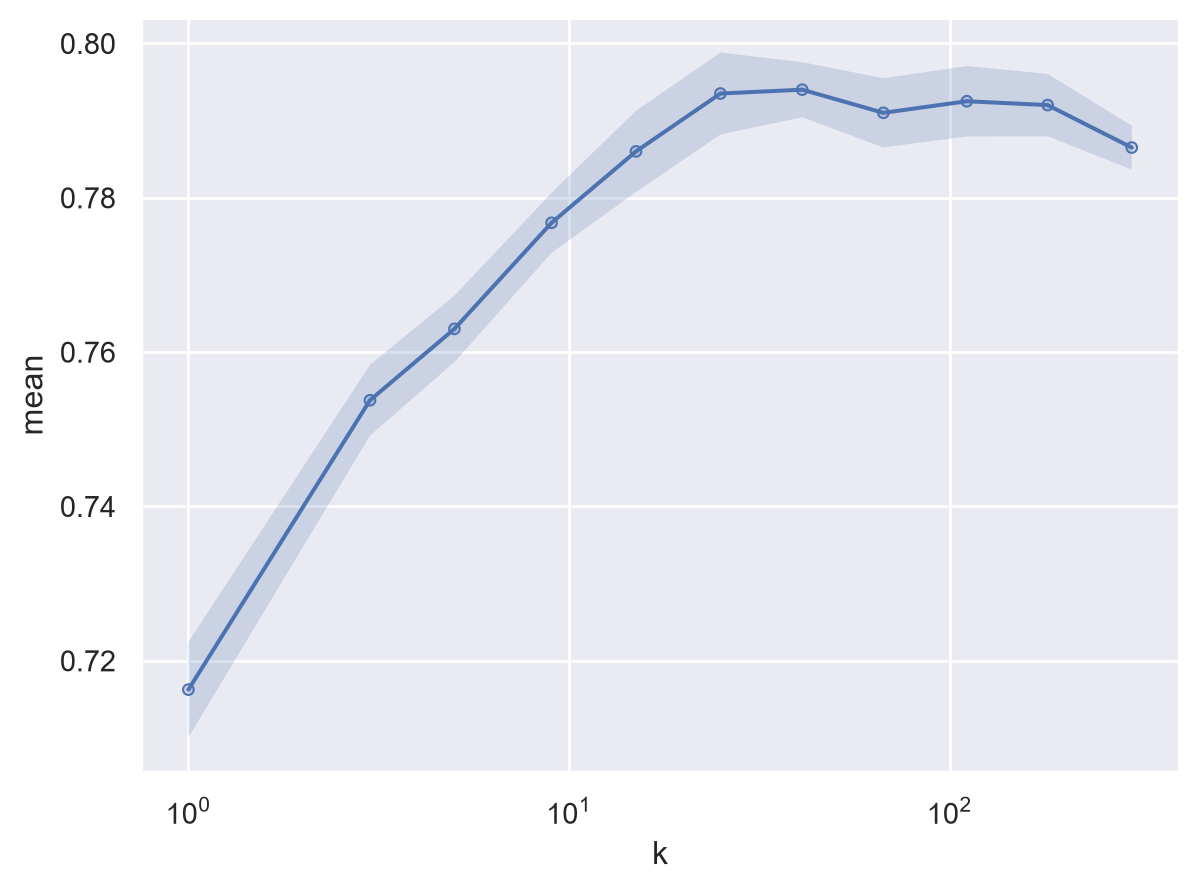

In [11]:
(so.Plot(summary, x='k', y='mean')
 .add(so.Line()).add(so.Dots())
 .add(so.Band(), ymin=summary['mean'] - summary['se'], ymax=summary['mean'] + summary['se'])
 .scale(x='log'))

**Conclusion** The best average accuracy ($0.794$) is obtained for $k = 41$, which also has the best worst fold. The one standard error rule selects a much simpler model, $k = 181$ (CV accuracy $0.792$, within one standard error of the best). On the test set, the three choices give $0.801$, $0.795$ and $0.801$: all the values of $k$ between about $25$ and $181$ have similar observed accuracies. The one-standard-error rule is a simplicity heuristic, and the rule mainly decides between simplicity and a (small, possibly illusory) gain. Note that the CV accuracy of the selected model is optimistic, as it is the maximum of $11$ noisy estimates (see the nested cross validation in *To go further*).

---

## 2. Unbalanced data, weights and costs

In our dataset, about one third of the loans are `Risk`, whereas we assume that in the real world the proportion of `Risk` is $\pi_{\text{Risk}} = 0.02$. If the conditional law of $X$ given $Y$ is the same in both worlds, an expectation in the real world is a *weighted* expectation in the training world, with a weight $w_y = \pi_y / \pi^{\text{train}}_y$ depending only on the class:
$$\mathbb{E}_{\text{real}}[\ell(Y, f(X))] = \mathbb{E}_{\text{train}}[w_Y\, \ell(Y, f(X))].$$

In [12]:
real_prop = {'Risk': .02, 'No Risk': .98}
train_prop = dict(y_train.value_counts(normalize=True).iter_rows())
custom_weight = {c: real_prop[c] / train_prop[c] for c in real_prop}
train_prop, custom_weight

({'Risk': 0.334, 'No Risk': 0.666},
 {'Risk': 0.059880239520958084, 'No Risk': 1.4714714714714714})

**Question** Write a function `custom_metric(y_true, y_pred)` computing the real-world accuracy (the weighted accuracy) and the corresponding scorer. What is the real-world accuracy of the logistic regression? Of a classifier that always predicts `No Risk`?

**Answer**

In [13]:
def compute_weights(y_true):
  return custom_weight['Risk'] * (y_true == 'Risk') + custom_weight['No Risk'] * (y_true == 'No Risk')

def custom_metric(y_true, y_pred):
  return 1 - (compute_weights(y_true) * (pl.Series(y_pred) != y_true)).mean()

custom_scorer = sklearn.metrics.make_scorer(custom_metric)
pipeline_log.fit(X_train, y_train)
{'logistic regression': custom_scorer(pipeline_log, X_test, y_test),
 'always No Risk': custom_metric(y_test, np.full(len(y_test), 'No Risk'))}

{'logistic regression': 0.8821546096995199, 'always No Risk': 0.98}

**Conclusion** The real-world accuracy of the logistic regression is only $0.88$, while a classifier that always predicts `No Risk` reaches $0.98$, the proportion of good loans in the real world. A classifier trained (and thresholded) for the proportions of the training set is badly suited to the real world.

---

Two ways of adapting the predictor are seen in the lecture: training with the weights (*weighted loss*), or keeping the probabilities estimated in the training world and changing the decision (*plug-in Bayes rule*): predict `Risk` when $w_{\text{Risk}}\, \hat{p}(\text{Risk}|x) > w_{\text{No Risk}}\, \hat{p}(\text{No Risk}|x)$.

To send weights to a step of a pipeline, `scikit-learn` uses *metadata routing*: each step declares whether it uses them.

**Question** Train the logistic regression with the weights (only the classifier should use them), and implement the plug-in decision. Compare their real-world accuracy on the test set.

**Answer** Once the routing is enabled, every step that *could* use the weights must say whether it does: here the scaler does not, the classifier does.

In [14]:
sklearn.set_config(enable_metadata_routing=True)

def make_weighted_pipeline(classifier):
  preprocessor_weighted = ColumnTransformer(transformers=[
      ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
      ('num', StandardScaler().set_fit_request(sample_weight=False), numerical_features)])
  return Pipeline(steps=[('preprocessor', preprocessor_weighted),
                         ('classifier', classifier.set_fit_request(sample_weight=True))]).set_output(transform="polars")

pipeline_log_weighted = make_weighted_pipeline(LogisticRegression(max_iter=1000))
pipeline_log_weighted.fit(X_train, y_train, sample_weight=compute_weights(y_train))

def custom_predict(pipeline, X):
  proba = pipeline.predict_proba(X)  # columns in the order of pipeline.classes_
  risk = list(pipeline.classes_).index('Risk')
  decision = custom_weight['Risk'] * proba[:, risk] > custom_weight['No Risk'] * proba[:, 1 - risk]
  return pl.Series(np.where(decision, 'Risk', 'No Risk'))

{'weighted training': custom_scorer(pipeline_log_weighted, X_test, y_test),
 'plug-in decision': custom_metric(y_test, custom_predict(pipeline_log, X_test))}

{'weighted training': 0.9816167664670659,
 'plug-in decision': 0.9807784431137725}

**Conclusion** Both adaptations reach a real-world accuracy of $0.98$ ($0.982$ for the weighted training, $0.981$ for the plug-in decision), i.e. the level of the trivial classifier: with these proportions, almost all the loans are predicted `No Risk`. The two sample accuracies are close. The population risk identity permits different finite-sample fits, especially with regularization or model misspecification. The accuracy is not the right criterion for this problem.

---

The accuracy is not the right criterion here: the cost of an error depends on the error and on the amount of the loan. We use the following cost model (the opposite of a gain):
- $5 + 0.6 \times \text{LoanAmount}$ if we grant a loan that defaults (`Risk` predicted `No Risk`),
- $1 - 0.05 \times \text{LoanAmount}$ if we grant a good loan (`No Risk` predicted `No Risk`): a benefit of $0.05 \times \text{LoanAmount}$ after a fixed cost of $1$,
- $1$ if we refuse the loan.

The cost model, the weighted cost metric and the corresponding scorers are gathered in `apm_credit.py`. The scorers return the *gain* (the opposite of the cost), and need `LoanAmount` as metadata:

In [15]:
import apm_credit
from apm_credit import cost_metric, cost_scorer, cost_scorer_from_proba, compute_cost_weights, compute_costs
apm_credit.set_proportions(y_train, real_prop)
LoanAmount_train, LoanAmount_test = X_train['LoanAmount'], X_test['LoanAmount']
cost_scorer(pipeline_log, X_test, y_test, LoanAmount=LoanAmount_test)

83.58840527953103

**Question** *Predict before you run.* Write the Bayes rule for this cost: for a loan of amount $a$ and an estimated probability $p$ of `Risk`, when should we refuse it? Compute the threshold on $p$ for a loan of $5000$, and compare it with the threshold $1/2$ of `predict`.

**Answer** We refuse the loan when the expected (weighted) cost of granting it is larger than the expected cost of refusing it:
$$w_{\text{Risk}}\, p\, (5 + 0.6 a) + w_{\text{No Risk}}\, (1-p)\, (1 - 0.05 a) > w_{\text{Risk}}\, p + w_{\text{No Risk}}\, (1 - p),$$
i.e. when $p > \tau(a) = \dfrac{w_{\text{No Risk}}\, (0.05 a)}{w_{\text{No Risk}}\, (0.05 a) + w_{\text{Risk}}\, (4 + 0.6 a)}$.

In [16]:
def bayes_threshold(a):
  regret_refuse = custom_weight['No Risk'] * 0.05 * a        # cost of refusing a good loan, minus the one of granting it
  regret_grant = custom_weight['Risk'] * (4 + 0.6 * a)       # cost of granting a defaulting loan, minus the one of refusing it
  return regret_refuse / (regret_refuse + regret_grant)
bayes_threshold(5000)

0.6716004362325112

**Conclusion** For a loan of $5000$, the Bayes rule refuses the loan when the estimated probability of `Risk` is above $0.672$, much more than the threshold $1/2$ of `predict`: as defaults are rare in the real world, a loan is refused only when the model is quite sure. As shown in PC1, this threshold hardly depends on the amount (it tends to $0.672$ for large amounts).

---

**Question** Compare, with a $5$-fold cross validation of the gain on the training set, the original logistic regression, the logistic regression trained with the cost weights `compute_cost_weights(y, LoanAmount)`, the Bayes decision on the probabilities of the original one (`cost_scorer_from_proba`), and a threshold tuned by cross validation (`TunedThresholdClassifierCV`). Which one would you choose? Evaluate it on the test set.

**Answer**

In [17]:
from sklearn.model_selection import TunedThresholdClassifierCV
pipeline_log_cost_weighted = make_weighted_pipeline(LogisticRegression(max_iter=1000))
pipeline_tuned = TunedThresholdClassifierCV(clone(pipeline_log), scoring=cost_scorer, cv=5)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_gains = pl.DataFrame({
  'original': cross_val_score(pipeline_log, X_train, y_train, cv=cv, scoring=cost_scorer,
                              params={'LoanAmount': LoanAmount_train}),
  'cost weighted': cross_val_score(pipeline_log_cost_weighted, X_train, y_train, cv=cv, scoring=cost_scorer,
                                   params={'LoanAmount': LoanAmount_train,
                                           'sample_weight': compute_cost_weights(y_train, LoanAmount_train)}),
  'Bayes decision': cross_val_score(pipeline_log, X_train, y_train, cv=cv, scoring=cost_scorer_from_proba,
                                    params={'LoanAmount': LoanAmount_train}),
  'tuned threshold': cross_val_score(pipeline_tuned, X_train, y_train, cv=cv, scoring=cost_scorer,
                                     params={'LoanAmount': LoanAmount_train})})
cv_gains.mean()

original,cost weighted,Bayes decision,tuned threshold
f64,f64,f64,f64
86.501282,96.346994,96.070744,96.270647


In [18]:
pipeline_log.fit(X_train, y_train)
cost_scorer_from_proba(pipeline_log, X_test, y_test, LoanAmount=LoanAmount_test)

94.47660392728059

**Conclusion** The original logistic regression has a CV gain of $86.5$. Taking the proportions and the costs into account improves it by about $10$ points, and the three approaches give similar observed gains: $96.3$ for the cost-weighted training, $96.1$ for the Bayes decision and $96.3$ for the tuned threshold (their differences are much smaller than the fold-to-fold variability). We choose the Bayes decision, which needs no extra training and adapts immediately if the costs or the proportions change. Its test gain is $94.5$, lower than its CV estimate but within the variability of a single test set.

---

## 3. Hyperparameter optimization with a fixed budget

We now tune a `HistGradientBoostingClassifier` (a model of Lecture 3, fast to train) for the cost-based gain of the Bayes decision. The lecture presents several strategies: an exhaustive grid, random search, *successive halving* (many candidates evaluated on small budgets, the best ones promoted to larger budgets), and Bayesian optimization (here Optuna's Tree-structured Parzen Estimator, TPE). We are going to compare them with roughly the same budget of $20$ full $3$-fold cross validations.

Note: `HistGradientBoostingClassifier` already uses several cores (we limited them to $2$ at the beginning of the lab); running several cross validations in parallel (`n_jobs`) on top of it oversubscribes them and is often *slower*, so we keep `n_jobs=None` here.

In [19]:
import time
import optuna
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.experimental import enable_halving_search_cv  # noqa: F401 (successive halving is still experimental)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, HalvingRandomSearchCV
from scipy.stats import loguniform, randint

pipeline_hgb = make_pipeline(HistGradientBoostingClassifier(random_state=0))
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
grid = {'classifier__learning_rate': [0.01, 0.05, 0.2, 1.0], 'classifier__max_leaf_nodes': [3, 7, 15, 31, 63]}
distributions = {'classifier__learning_rate': loguniform(0.01, 1), 'classifier__max_leaf_nodes': randint(3, 64)}

~\.venvs\apm50441\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Question** Run a grid search on the $4 \times 5$ grid `grid`, a random search with $20$ draws from `distributions`, a successive halving search (`HalvingRandomSearchCV` with $60$ candidates, `factor=3` and `min_resources='exhaust'`, the resource being the number of training samples) and an Optuna study with $20$ trials of a TPE sampler, all with the gain of the Bayes decision (`cost_scorer_from_proba`) as score. Compare their best CV gains, their running times, and the gains of the selected models on the test set.

**Answer** The searches of `scikit-learn` route `LoanAmount` to the scorer; with Optuna, we write the objective ourselves.

In [20]:
searches, timings = {}, {}
for name, search in {
    'grid': GridSearchCV(pipeline_hgb, grid, cv=cv3, scoring=cost_scorer_from_proba),
    'random': RandomizedSearchCV(pipeline_hgb, distributions, n_iter=20, cv=cv3, scoring=cost_scorer_from_proba,
                                 random_state=0),
    'successive halving': HalvingRandomSearchCV(pipeline_hgb, distributions, n_candidates=60, factor=3,
                                                min_resources='exhaust', cv=cv3, scoring=cost_scorer_from_proba,
                                                random_state=0)}.items():
  start = time.perf_counter()
  searches[name] = search.fit(X_train, y_train, LoanAmount=LoanAmount_train)
  timings[name] = time.perf_counter() - start

In [21]:
def objective(trial):
  params = {'classifier__learning_rate': trial.suggest_float('learning_rate', 0.01, 1, log=True),
            'classifier__max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 3, 63)}
  return cross_val_score(clone(pipeline_hgb).set_params(**params), X_train, y_train, cv=cv3,
                         scoring=cost_scorer_from_proba, params={'LoanAmount': LoanAmount_train}).mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
start = time.perf_counter()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=20)
timings['TPE (Optuna)'] = time.perf_counter() - start
best_tpe = clone(pipeline_hgb).set_params(classifier__learning_rate=study.best_params['learning_rate'],
                                          classifier__max_leaf_nodes=study.best_params['max_leaf_nodes']).fit(X_train, y_train)

In [22]:
best_models = {name: search.best_estimator_ for name, search in searches.items()} | {'TPE (Optuna)': best_tpe}
best_cv = {name: search.best_score_ for name, search in searches.items()} | {'TPE (Optuna)': study.best_value}
pl.DataFrame([{'search': name, 'time (s)': timings[name], 'best CV gain': best_cv[name],
               'test gain': cost_scorer_from_proba(model, X_test, y_test, LoanAmount=LoanAmount_test)}
              for name, model in best_models.items()])

search,time (s),best CV gain,test gain
str,f64,f64,f64
"""grid""",37.309092,96.193296,97.441249
"""random""",55.388762,96.168754,95.656648
"""successive halving""",80.443999,93.471173,95.26634
"""TPE (Optuna)""",56.642823,96.16606,96.386566


**Conclusion** With the same budget, the grid search, the random search and the TPE reach the same best CV gain ($96.2$); the successive halving only reaches $93.5$: its first rounds evaluate the $60$ candidates on very few loans, where the cost-based gain (driven by a few large defaults) is very noisy, and good candidates are eliminated early. Successive halving pays off when the ranking on small budgets is reliable, which is not the case here. Their running times are of the same order (from about $40$ to $80$ s here; the timings depend on the machine and its load). The test gains vary more ($95.3$ to $97.4$) than the CV gains, and their ranking differs: the differences between the searches are within the noise of a single test set. With two hyperparameters and this budget, all the strategies work; the advantage of random search and TPE over a grid appears with more hyperparameters, few of which really matter (Bergstra and Bengio).

---

To measure sensitivity to the fold assignment, select the best configuration using shuffle A and score it using shuffle B of the same 400 loans. Both shuffles reuse all observations.

**Question** Draw $60$ random configurations from `distributions`. For each of them, compute the $3$-fold CV gain on the small training set with two different shuffles (A and B). As a function of the number $m$ of configurations tried, plot the best CV gain on A (the reported one) and the CV gain on B of the configuration selected on A. Comment.

**Answer**

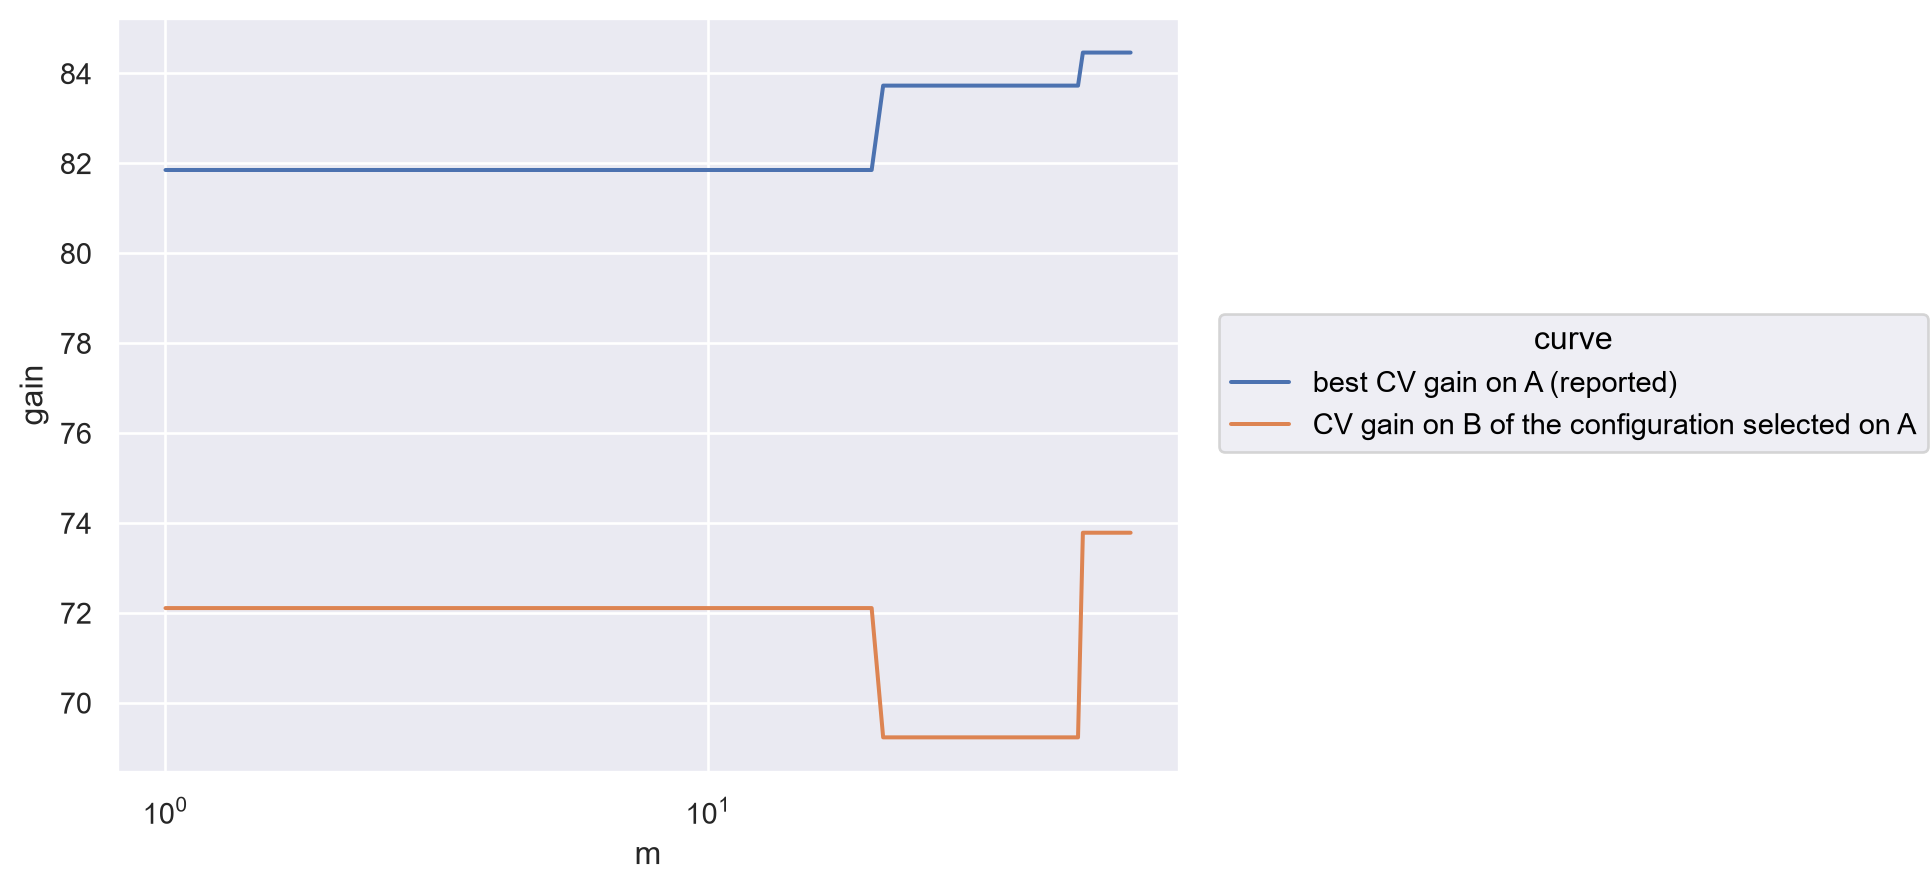

In [23]:
from sklearn.model_selection import ParameterSampler
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=400, random_state=0, stratify=y_train)
configurations = list(ParameterSampler(distributions, n_iter=60, random_state=1))
folds = {'A': StratifiedKFold(n_splits=3, shuffle=True, random_state=10), 'B': StratifiedKFold(n_splits=3, shuffle=True, random_state=11)}
trials = pl.DataFrame([{f'CV gain {name}': cross_val_score(clone(pipeline_hgb).set_params(**params), X_small, y_small, cv=cv,
                                                             scoring=cost_scorer_from_proba,
                                                             params={'LoanAmount': X_small['LoanAmount']}).mean()
                        for name, cv in folds.items()} for params in configurations])
selected = [int(trials['CV gain A'][:m].arg_max()) for m in range(1, len(trials) + 1)]
curves = pl.DataFrame({'m': range(1, len(trials) + 1),
                       'best CV gain on A (reported)': trials['CV gain A'].to_numpy()[selected],
                       'CV gain on B of the configuration selected on A': trials['CV gain B'].to_numpy()[selected]})
so.Plot(curves.unpivot(index='m', variable_name='curve', value_name='gain'), x='m', y='gain', color='curve').add(so.Line()).scale(x='log')

In [24]:
curves.filter(pl.col('m').is_in([1, 5, 10, 30, 60])).with_columns(
    (pl.col('best CV gain on A (reported)') - pl.col('CV gain on B of the configuration selected on A')).alias('optimism'))

m,best CV gain on A (reported),CV gain on B of the configuration selected on A,optimism
i64,f64,f64,f64
1,81.853409,72.109734,9.743675
5,81.853409,72.109734,9.743675
10,81.853409,72.109734,9.743675
30,83.7301,69.234329,14.495771
60,84.465305,73.785767,10.679538


**Conclusion** The best gain on A rises from $81.9$ to $84.5$ over the search, while the selected configurations score between $69$ and $74$ on B. Even the first configuration can score differently across shuffles. This experiment measures split sensitivity. Isolating selection optimism requires disjoint evaluation data, for example an outer validation fold.

---

## 4. Validation of a time series forecast

We forecast the monthly CO$_2$ concentration at Mauna Loa (1958–2001, bundled with `statsmodels`) **one year ahead**: at the end of month $t$, we want $y_{t+12}$. Only the values up to time $t$ can be used, so the features of the target $y_s$ can only use $y_{s-12}, y_{s-13}, \dots$ (the *lags* larger than the horizon), the calendar (month) and the time.

The last $10$ years (1992–2001) are kept as a test period. Freeze the fit in December 1990, before the January 1991 origin of the first forecast.

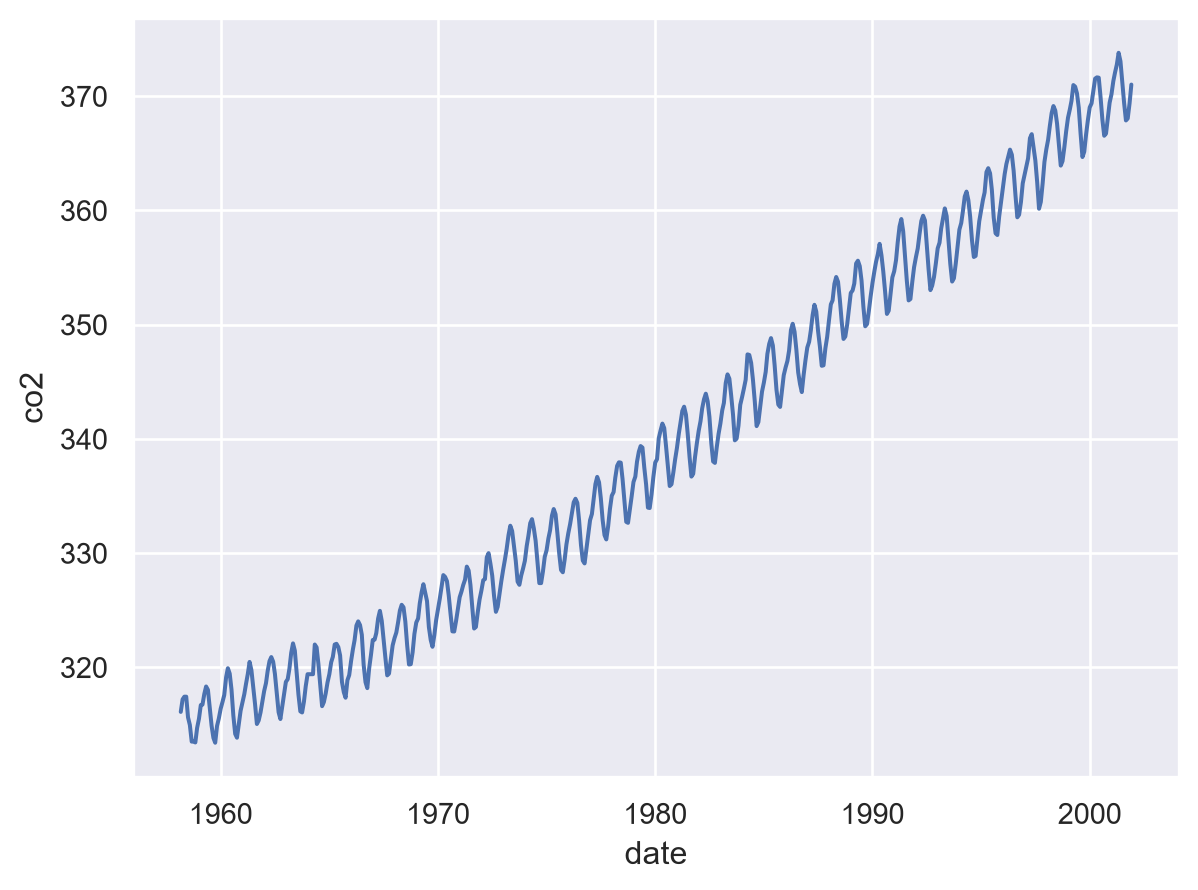

In [25]:
import statsmodels.api as sm
co2 = sm.datasets.co2.load_pandas().data['co2'].resample('MS').mean().ffill()
co2 = pl.DataFrame({'date': co2.index.to_numpy(), 'co2': co2.to_numpy()})
H = 12  # forecast horizon (months)
co2_features = (co2.with_columns(pl.col('date').dt.month().alias('month'),
                                 ((pl.col('date').dt.year() - 1958) + (pl.col('date').dt.month() - 1) / 12).alias('time'),
                                 *[pl.col('co2').shift(lag).alias(f'lag_{lag}') for lag in range(H, H + 13)])
                .with_columns(*[f(2 * np.pi * k * pl.col('month') / 12).alias(f'{f.__name__}_{k}')
                                for k in (1, 2) for f in (np.sin, np.cos)])
                .drop_nulls())
train_ts = co2_features.filter(pl.col('date').dt.year() < 1991)
test_ts = co2_features.filter(pl.col('date').dt.year() >= 1992)
features = ['time', 'sin_1', 'cos_1', 'sin_2', 'cos_2'] + [f'lag_{lag}' for lag in range(H, H + 13)]
so.Plot(co2, x='date', y='co2').add(so.Line())

**Question** The *seasonal naive* forecast predicts $y_{t+12}$ by $y_t$, i.e. $\hat{y}_s = y_{s-12}$ (`lag_12`). Compute its mean absolute error (MAE) on the test period. Then fit a ridge regression and a `HistGradientBoostingRegressor` on the `features`, and compute their test MAE.

**Answer**

In [26]:
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
models_ts = {'ridge': Pipeline([('scaler', StandardScaler()), ('model', RidgeCV(alphas=np.logspace(-3, 3, 13)))]),
             'gradient boosting': HistGradientBoostingRegressor(random_state=0)}
test_mae = {'seasonal naive': mean_absolute_error(test_ts['co2'], test_ts['lag_12'])}
for name, model in models_ts.items():
  model.fit(train_ts[features], train_ts['co2'])
  test_mae[name] = mean_absolute_error(test_ts['co2'], model.predict(test_ts[features]))
test_mae

{'seasonal naive': 1.5303333333333327,
 'ridge': 0.6615587633291853,
 'gradient boosting': 9.007799972137109}

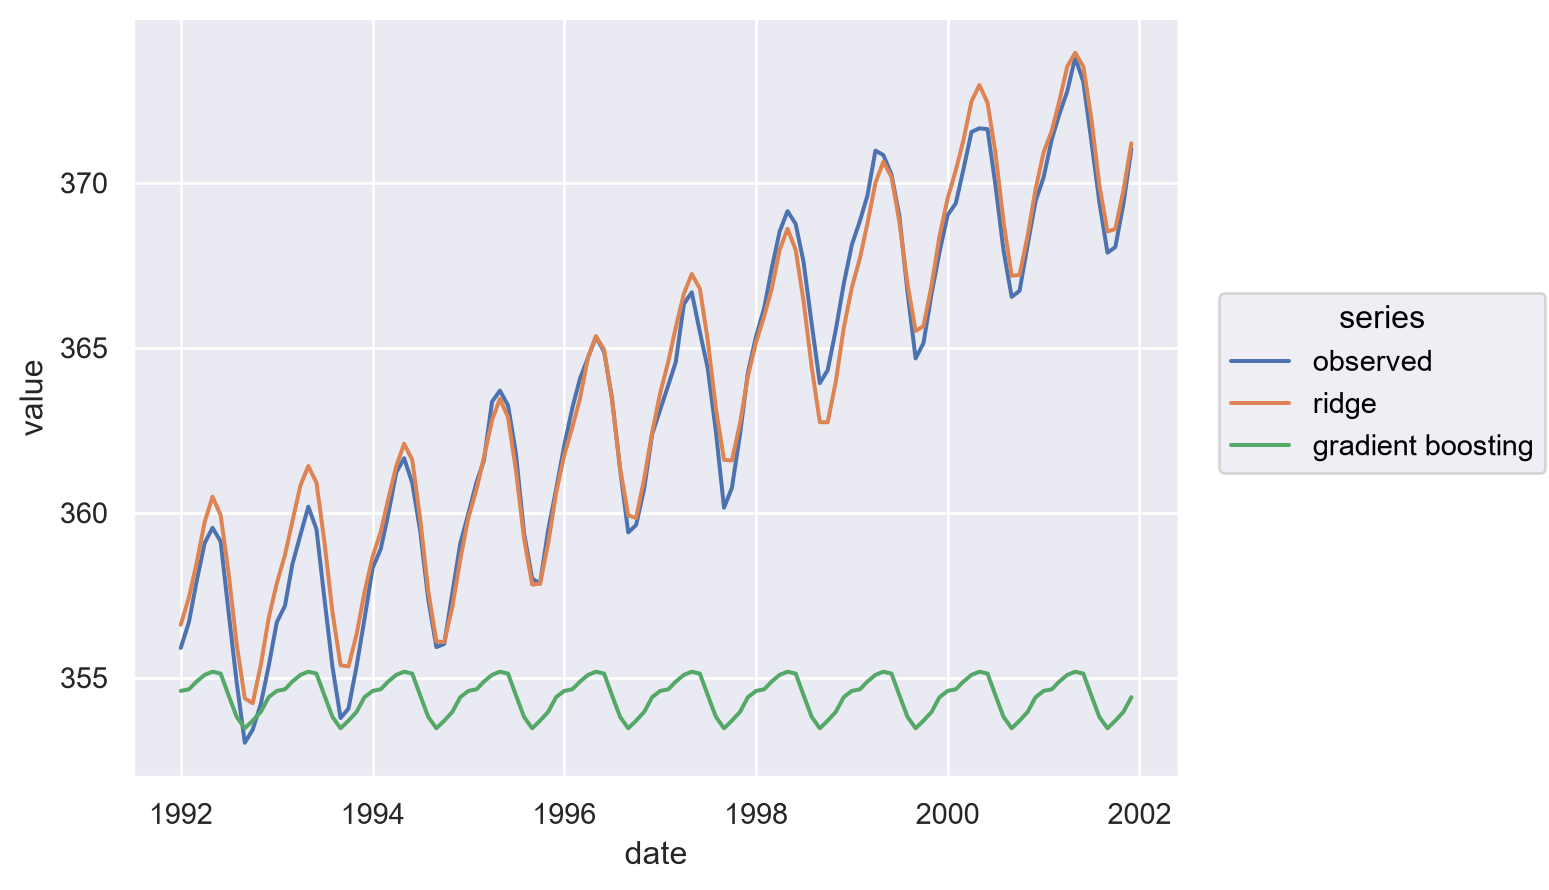

In [27]:
predictions = pl.concat([test_ts.select('date', pl.col('co2').alias('value'), pl.lit('observed').alias('series'))]
                        + [test_ts.select('date', pl.Series('value', model.predict(test_ts[features])), pl.lit(name).alias('series'))
                           for name, model in models_ts.items()])
so.Plot(predictions, x='date', y='value', color='series').add(so.Line())

**Conclusion** Across the 120 test months the seasonal naive forecast has MAE $1.53$ ppm. Ridge reduces this to $0.66$ ppm. Boosting on levels gives $9.01$ ppm because the trees cannot extrapolate the long-run trend beyond the training range.

---

**Question** *Predict before you run.* We want to choose between these models with the training period only. Compare the MAE estimated by a shuffled $5$-fold cross validation, by `TimeSeriesSplit(n_splits=5, test_size=24, gap=H)` (each validation block comes after its training part, with a gap of at least the horizon), and the test MAE. Which estimation is reliable?

**Answer**

In [28]:
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
splitters = {'shuffled 5-fold': KFold(n_splits=5, shuffle=True, random_state=0),
             'time series split (gap = H)': TimeSeriesSplit(n_splits=5, test_size=24, gap=H)}
cv_mae = [{'model': name, 'estimation': split_name,
           'MAE': -cross_val_score(model, train_ts[features], train_ts['co2'], cv=splitter,
                                   scoring='neg_mean_absolute_error').mean()}
          for name, model in models_ts.items() for split_name, splitter in splitters.items()]
cv_mae += [{'model': name, 'estimation': 'test period', 'MAE': test_mae[name]} for name in models_ts]
pl.DataFrame(cv_mae).pivot(index='model', on='estimation', values='MAE')

model,shuffled 5-fold,time series split (gap = H),test period
str,f64,f64,f64
"""ridge""",0.443092,0.416968,0.661559
"""gradient boosting""",0.502082,3.426197,9.0078


**Conclusion** Shuffled CV gives MAEs of $0.44$ ppm for ridge and $0.50$ for boosting. Forward CV with a 12-month gap gives $0.42$ and $3.43$, respectively. Both splits rank ridge first, but shuffled CV substantially understates the cost of extrapolation for boosting. Even the forward blocks are shorter than the ten-year test period.

---

**Question** Trees cannot extrapolate: the gradient boosting predicts values in the range of its training targets. *Stationarize* the series by forecasting the seasonal difference $y_{t+12} - y_t$ (i.e. predict `co2 - lag_12` and add `lag_12` back), and compare the test MAE of both models.

**Answer**

In [29]:
target_diff = train_ts['co2'] - train_ts['lag_12']
for name, model in models_ts.items():
  model.fit(train_ts[features], target_diff)
  test_mae[name + ' (seasonal difference)'] = mean_absolute_error(test_ts['co2'], test_ts['lag_12'] + model.predict(test_ts[features]))
pl.DataFrame({'model': list(test_mae), 'test MAE': list(test_mae.values())}).sort('test MAE')

model,test MAE
str,f64
"""ridge (seasonal difference)""",0.622245
"""gradient boosting (seasonal di…",0.639772
"""ridge""",0.661559
"""seasonal naive""",1.530333
"""gradient boosting""",9.0078


**Conclusion** Predicting the seasonal difference reduces boosting MAE from $9.01$ to $0.64$ ppm and ridge MAE from $0.66$ to $0.62$. Adding the latest available seasonal level back to the prediction lets both models track the rising series.

---

## To go further

The following blocks are optional and independent: each of them only uses the objects defined in the core part. Their difficulty is marked by stars: ★ direct extension, ★★ new method, ★★★ longer or research-flavored.

| Block | Lecture | Stars |
|---|---|---|
| Bootstrap estimates: .632 and .632+ | Risk estimation | ★ |
| The number of folds and leave-one-out | Risk estimation | ★ |
| Penalized criteria: AIC and BIC | Risk correction | ★ |
| Nested cross validation | CV and test | ★★ |
| McNemar's test and the lucky winner | Comparison of means | ★★ |
| Resampling instead of weights | Unbalanced data | ★★ |
| Calibration and cost-based decisions | Weighted loss | ★★ |
| The geometry of cost-sensitive decisions | Weighted loss | ★★ |
| Pruning and other samplers in Optuna | AutoML | ★★ |
| AutoML frameworks and stacking | AutoML | ★★ |
| A tabular foundation model: AutoML without search | AutoML, meta-learning | ★★ |
| STL decomposition | Time series | ★ |
| ARIMA models | Time series | ★★ |
| Prediction intervals | Time series | ★★ |
| A small neural forecaster | Time series | ★★ |
| Zero-shot forecasting with a foundation model | Time series | ★★★ |

The packages used in these blocks (not needed for the core) are installed here:

In [30]:
import sys
!uv pip install --python "{sys.executable}" "flaml[automl]==2.6.0" "cmaes==0.13.1" "tabicl==2.1.1" "chronos-forecasting==2.3.2" "torch"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 5 packages in 117ms


### Bootstrap estimates: .632 and .632+ (★)

The bootstrap draws $n$ observations with replacement: about $63.2\%$ of the distinct observations are drawn, the others (*out-of-bag*, OOB) can be used for validation. The OOB error is pessimistic (each model is trained on about $63\%$ of the data) while the training error is optimistic; the *.632 estimate* $0.368\,\widehat{\text{err}}_{\text{train}} + 0.632\,\widehat{\text{err}}_{\text{OOB}}$ mixes them. When the model overfits a lot, the *.632+ estimate* gives more weight to the OOB error, with a weight depending on the *relative overfitting rate* $R = (\widehat{\text{err}}_{\text{OOB}} - \widehat{\text{err}}_{\text{train}})/(\gamma - \widehat{\text{err}}_{\text{train}})$, where $\gamma$ is the *no-information error rate* (the error when the labels are independent of the features): $\hat{w} = 0.632/(1 - 0.368 R)$.

**Question** For the $1$-NN, the $15$-NN and the logistic regression, compute the training error, the OOB error (with $50$ bootstrap samples), the .632 and .632+ estimates, and compare them with the test error.

**Answer**

In [31]:
rng = np.random.default_rng(0)
X_train_np_index = np.arange(len(X_train))
def bootstrap_estimates(pipeline, B=50):
  model = clone(pipeline).fit(X_train, y_train)
  err_train = 1 - model.score(X_train, y_train)
  oob_errors = []
  for b in range(B):
    idx = rng.choice(X_train_np_index, size=len(X_train), replace=True)
    oob = np.setdiff1d(X_train_np_index, idx)
    fitted = clone(pipeline).fit(X_train[idx], y_train[idx])
    oob_errors.append(1 - fitted.score(X_train[oob], y_train[oob]))
  err_oob = np.mean(oob_errors)
  p = (y_train == 'Risk').mean()                        # proportion of Risk
  q = (model.predict(X_train) == 'Risk').mean()         # proportion of Risk predictions
  gamma = p * (1 - q) + (1 - p) * q                     # no-information error rate
  R = np.clip((err_oob - err_train) / (gamma - err_train), 0, 1) if gamma > err_train else 0
  w = 0.632 / (1 - 0.368 * R)
  return {'training error': err_train, 'OOB error': err_oob, '.632': 0.368 * err_train + 0.632 * err_oob,
          '.632+': (1 - w) * err_train + w * err_oob, 'test error': 1 - model.score(X_test, y_test)}

pl.DataFrame([{'model': name} | bootstrap_estimates(pipeline)
              for name, pipeline in {'1-NN': make_pipeline(KNeighborsClassifier(n_neighbors=1)),
                                     '15-NN': pipeline_nn, 'logistic': make_pipeline(LogisticRegression(max_iter=1000))}.items()])

model,training error,OOB error,.632,.632+,test error
str,f64,f64,f64,f64,f64
"""1-NN""",0.0,0.286315,0.180951,0.237105,0.261
"""15-NN""",0.1905,0.232073,0.216774,0.218671,0.202
"""logistic""",0.19725,0.206663,0.203199,0.20329,0.2


**Conclusion** For the $1$-NN, the training error is $0$ and the OOB error ($0.29$) is pessimistic (each bootstrap model sees about $63\%$ of the distinct observations). The .632 estimate ($0.18$) is too optimistic, as it gives a weight of $0.368$ to a meaningless training error; the .632+ estimate ($0.24$), which gives more weight to the OOB error when the model overfits, is close to the test error ($0.26$). For the $15$-NN and the logistic regression, which overfit little, all the estimates are close to the test error ($0.20$).

---

### The number of folds and leave-one-out (★)

With $V$ folds, each model is trained on a fraction $(V-1)/V$ of the data: a small $V$ gives a pessimistic estimate (less training data), a large $V$ gives more correlated models. For a linear regression, the leave-one-out (LOO, $V=n$) error has a closed form: the residual of the observation $i$ when it is left out is $(Y_i - \hat{Y}_i)/(1 - h_{ii})$, where $h_{ii}$ is the $i$-th diagonal element of the *hat matrix* $\mathbb{X}(\mathbb{X}^\top\mathbb{X})^{-1}\mathbb{X}^\top$.

**Question** (a) For the logistic regression, compute the $V$-fold CV accuracy for $V \in \{2, 5, 10, 20\}$, repeated $5$ times with different shuffles: how do the average and the spread across repetitions depend on $V$?
(b) Predict `LoanAmount` from the other numerical features with a linear regression on $500$ loans: check the closed form of the LOO error against $500$ fits.

**Answer**

In [32]:
from sklearn.model_selection import KFold
v_results = pl.DataFrame([{'V': V, 'rep': rep,
                           'CV accuracy': cross_val_score(pipeline_log, X_train, y_train,
                                                          cv=StratifiedKFold(n_splits=V, shuffle=True, random_state=rep),
                                                          n_jobs=2).mean()}
                          for V in [2, 5, 10, 20] for rep in range(5)])
v_results.group_by('V').agg(pl.col('CV accuracy').mean().alias('mean'), pl.col('CV accuracy').std().alias('sd across repetitions')).sort('V')

V,mean,sd across repetitions
i64,f64,f64
2,0.79485,0.002212
5,0.7961,0.002356
10,0.79555,0.00143
20,0.7963,0.001022


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
small = X_train.head(500)
Xr = np.column_stack([np.ones(500), small.select(pl.exclude('LoanAmount')).select(cs.numeric()).to_numpy()])
yr = small['LoanAmount'].to_numpy()
hat = Xr @ np.linalg.solve(Xr.T @ Xr, Xr.T)
residuals = yr - hat @ yr
loo_closed_form = np.mean((residuals / (1 - np.diag(hat))) ** 2)
loo_brute_force = -cross_val_score(LinearRegression(), Xr[:, 1:], yr, cv=LeaveOneOut(), scoring='neg_mean_squared_error').mean()
loo_closed_form, loo_brute_force

(np.float64(1969263.92722138), np.float64(1969263.92722138))

**Conclusion** The mean CV accuracy hardly depends on $V$ ($0.795$ to $0.796$): the logistic regression is stable, and training on $50\%$ or $95\%$ of the data changes little. The variability across repetitions decreases with $V$ ($0.0022$ for $V=2$, $0.0010$ for $V=20$), as each estimate averages more folds. For the linear regression, the closed form and the $500$ fits give exactly the same leave-one-out error: LOO costs a single fit for least squares (PC1, *Leave-one-out for least squares*).

---

### Penalized criteria: AIC and BIC (★)

Instead of estimating the risk on new data, one can correct the training risk by a penalty: for a model with $d$ parameters fitted by maximum likelihood, $\text{AIC} = -2\log\mathcal{L} + 2d$ and $\text{BIC} = -2\log\mathcal{L} + d \log n$ (the smaller, the better). They only need one fit per model.

**Question** Fit logistic regressions (with `statsmodels`) on nested sets of features: the numerical features only, then adding the categorical features one by one (in the order of the columns). Compare the models selected by AIC, by BIC, and by a $5$-fold CV of the log loss.

**Answer**

In [34]:
import statsmodels.api as sm
from sklearn.metrics import log_loss
y01 = (y_train == 'Risk').to_numpy().astype(float)
feature_sets = [numerical_features] + [numerical_features + categorical_features[:j] for j in range(1, len(categorical_features) + 1)]
def design(X, feature_set):
  categorical = [f for f in feature_set if f in categorical_features]
  table = X.select(feature_set)
  if categorical:
    table = table.to_dummies(columns=categorical, drop_first=True)
  return sm.add_constant(table.to_numpy().astype(float), has_constant='add')

def unpenalized_logistic(categorical):
  encoder = ColumnTransformer([('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical),
                               ('num', StandardScaler(), numerical_features)])
  return Pipeline([('preprocessor', encoder), ('classifier', LogisticRegression(C=np.inf, max_iter=5000))])

criteria = []
for feature_set in feature_sets:
  fit = sm.Logit(y01, design(X_train, feature_set)).fit(disp=0, maxiter=500)
  cv_log_loss = -cross_val_score(unpenalized_logistic([f for f in feature_set if f in categorical_features]),
                                 X_train, y_train, cv=5, scoring='neg_log_loss').mean()
  criteria.append({'last feature added': feature_set[-1], 'parameters': int(fit.df_model) + 1,
                   'AIC': fit.aic, 'BIC': fit.bic, 'CV log loss': cv_log_loss})
criteria = pl.DataFrame(criteria)
criteria

~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


... (3 outputs left out)

~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


~\.venvs\apm50441\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


last feature added,parameters,AIC,BIC,CV log loss
str,i64,f64,f64,f64
"""Dependents""",8,3792.43004,3842.782437,0.47585
"""CheckingStatus""",11,3780.991471,3850.226017,0.475322
"""CreditHistory""",15,3738.714009,3833.124754,0.469625
"""LoanPurpose""",25,3748.613637,3905.964878,0.471667
"""ExistingSavings""",29,3740.188923,3922.716362,0.470992
…,…,…,…,…
"""InstallmentPlans""",41,3407.130132,3665.186168,0.429612
"""Housing""",43,3406.853754,3677.497888,0.42974
"""Job""",46,3410.337188,3699.863471,0.43002


In [35]:
{criterion: criteria['last feature added'][int(criteria[criterion].arg_min())] for criterion in ['AIC', 'BIC', 'CV log loss']}

{'AIC': 'Telephone', 'BIC': 'InstallmentPlans', 'CV log loss': 'ForeignWorker'}

**Conclusion** AIC selects a large model ($47$ parameters, up to `Telephone`), BIC a smaller one ($41$ parameters, up to `InstallmentPlans`), as its penalty $d \log n$ is larger than $2d$ for $n = 4000$; the cross validation of the log loss selects the full model, but its values for the last models differ by less than $0.001$. The three criteria agree on the important part: adding the first features improves the fit a lot, adding the last ones changes almost nothing.

---

### Nested cross validation (★★)

The CV score of the selected $k$ is optimistic, as it is the best of several candidates evaluated on the same folds. *Nested* cross validation estimates the performance of the whole procedure, selection included: an outer cross validation splits the training set, and on each outer training part an inner cross validation (`GridSearchCV`) selects $k$; the selected model is evaluated on the outer validation part.

**Question** Estimate by nested cross validation the accuracy of the selection of $k$ (best mean rule) among `n_neighbors_values`, and compare it with the best CV accuracy of the core part. Which $k$ is selected in each outer fold?

**Answer**

In [36]:
from sklearn.model_selection import GridSearchCV, cross_validate
inner = GridSearchCV(make_pipeline(KNeighborsClassifier()), {'classifier__n_neighbors': n_neighbors_values}, cv=5, n_jobs=2)
nested = cross_validate(inner, X_train, y_train, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=1), return_estimator=True)
print('selected k:', [estimator.best_params_['classifier__n_neighbors'] for estimator in nested['estimator']])
{'best CV accuracy (core part)': summary['mean'].max(), 'nested CV accuracy': nested['test_score'].mean()}

selected k: [25, 25, 111, 67, 41]


{'best CV accuracy (core part)': 0.7939999999999999,
 'nested CV accuracy': np.float64(0.791)}

**Conclusion** The outer folds select different numbers of neighbors ($25$, $25$, $111$, $67$, $41$): the accuracy is flat around its maximum. The nested cross validation estimates the accuracy of the whole selection procedure at $0.791$, slightly below the best CV accuracy of the core part ($0.794$): the selection bias is small here (the candidates have close accuracies and are evaluated on $4000$ loans), but it would be larger with more candidates or less data.

---

### McNemar's test and the lucky winner (★★)

On a single test set, two classifiers can be compared with McNemar's test, which only looks at the observations on which they disagree: if they were equally good, each of them would be the only one right on those observations with probability $1/2$. When *many* models are compared, the best one is partly the luckiest one: this is the *lucky winner* of the lecture.

**Question** (a) Apply McNemar's test to the logistic regression and the $15$-NN on the test set.
(b) Simulate the lucky winner: draw $20$ "models" that predict `Risk` at random with the same rate as the logistic regression, keep the best one on the first half of the test set, and evaluate it on the second half. Repeat $200$ times.

**Answer**

In [37]:
correct_log = clone(pipeline_log).fit(X_train, y_train).predict(X_test) == y_test.to_numpy()
correct_nn = clone(pipeline_nn).fit(X_train, y_train).predict(X_test) == y_test.to_numpy()
only_log, only_nn = int(np.sum(correct_log & ~correct_nn)), int(np.sum(~correct_log & correct_nn))
print('only logistic right:', only_log, '| only 15-NN right:', only_nn)
stats.binomtest(only_log, only_log + only_nn, p=0.5).pvalue

only logistic right: 45 | only 15-NN right: 43


np.float64(0.9151865048428764)

In [38]:
rng = np.random.default_rng(0)
truth = (y_test == 'Risk').to_numpy()
rate = (clone(pipeline_log).fit(X_train, y_train).predict(X_test) == 'Risk').mean()
half = len(truth) // 2
winners = []
for _ in range(200):
  predictions = rng.random((20, len(truth))) < rate
  accuracy = (predictions == truth).astype(float)
  best = accuracy[:, :half].mean(axis=1).argmax()
  winners.append({'best on first half': accuracy[best, :half].mean(), 'same model on second half': accuracy[best, half:].mean()})
pl.DataFrame(winners).mean()

best on first half,same model on second half
f64,f64
0.60621,0.57208


**Conclusion** On the test set, the two models disagree on $88$ loans: the logistic regression is right on $45$ of them, the $15$-NN on $43$, and McNemar's test gives $p = 0.92$: a test set of $1000$ loans cannot separate them. In the simulation, the best of $20$ random classifiers has an accuracy of $0.606$ on the half used for the selection, but only $0.572$ on the other half, the expected accuracy of a random classifier: its advantage was pure luck. This is the *lucky winner* of the lecture, and the reason why a selected model must be evaluated on data not used for the selection.

---

### Resampling instead of weights (★★)

Instead of weights, the proportions of the training set can be changed by *resampling*: undersampling the majority class, oversampling the minority class, or generating synthetic minority observations (SMOTE). Here the real world has *fewer* `Risk` than the training set, so the resampling goes the other way: the `Risk` class is undersampled (or the `No Risk` class oversampled) to reach $2\%$ of `Risk`.

**Question** Train the logistic regression on a training set resampled to the real proportions, by undersampling `Risk` (drawing without replacement) and by oversampling `No Risk` (drawing with replacement), and compare their real-world accuracy and their gain (with `cost_scorer`) with the weighted training. Which drawback of undersampling appears?

(The `imbalanced-learn` package provides these resamplers, as well as SMOTE, but it is not compatible with the metadata routing of `scikit-learn` that we enabled, so we need to resample by hand with `polars`.)

**Answer**

In [39]:
training = X_train.with_columns(y_train)
risk, no_risk = training.filter(pl.col('Risk') == 'Risk'), training.filter(pl.col('Risk') == 'No Risk')
resampled_sets = {
  'undersampling Risk': pl.concat([risk.sample(n=int(round(len(no_risk) * 0.02 / 0.98)), seed=0), no_risk]),
  'oversampling No Risk': pl.concat([risk, no_risk.sample(n=int(round(len(risk) * 0.98 / 0.02)), with_replacement=True, seed=0)])}
resampling = []
for name, resampled in resampled_sets.items():
  y_res = resampled['Risk']
  model = clone(pipeline_log).fit(resampled.drop('Risk'), y_res)
  resampling.append({'training': name, 'training size': len(y_res), 'real-world accuracy': custom_scorer(model, X_test, y_test),
                     'gain': cost_scorer(model, X_test, y_test, LoanAmount=LoanAmount_test)})
resampling.append({'training': 'weighted', 'training size': len(y_train), 'real-world accuracy': custom_scorer(pipeline_log_weighted, X_test, y_test),
                   'gain': cost_scorer(pipeline_log_weighted, X_test, y_test, LoanAmount=LoanAmount_test)})
pl.DataFrame(resampling)

training,training size,real-world accuracy,gain
str,i64,f64,f64
"""undersampling Risk""",2718,0.979786,73.332673
"""oversampling No Risk""",66800,0.982275,77.97509
"""weighted""",4000,0.981617,75.289593


**Conclusion** Undersampling the `Risk` class to $2\%$ keeps only $54$ of the $1336$ defaults: the training set shrinks to $2718$ loans and most of the information on the minority class is thrown away. Oversampling `No Risk` creates a training set of $66800$ loans by duplicating the same $2664$ good loans. Both reach the same real-world accuracy as the weighted training ($0.98$), and similar gains ($73$ to $78$; these models only take the proportions into account, not the costs). Weights give the same expected loss without losing nor duplicating data, which is why they are usually preferred; resampling remains useful for methods that do not accept weights.

---

### Calibration and cost-based decisions (★★)

The Bayes decision uses the estimated probabilities as if they were the true conditional probabilities. A classifier is *calibrated* when, among the loans to which it gives a probability $p$ of `Risk`, a proportion $p$ are indeed `Risk`. This can be checked with a reliability diagram and with *proper scores* (Brier score, log loss), and improved by learning a monotone mapping of the scores by cross validation (`CalibratedClassifierCV`).

**Question** Compare the calibration of the logistic regression, of the $15$-NN and of the gradient boosting selected by the grid search. Calibrate the $15$-NN (isotonic) and the gradient boosting (sigmoid): do their Bayes decisions gain more?

**Answer**

model,Brier score,log loss,gain (Bayes decision)
str,f64,f64,f64
"""logistic""",0.135178,0.414356,94.476604
"""15-NN""",0.143756,0.599254,92.103413
"""gradient boosting""",0.136206,0.420307,97.441249
"""15-NN, isotonic""",0.139803,0.431485,94.614834
"""gradient boosting, sigmoid""",0.13524,0.416774,96.343545


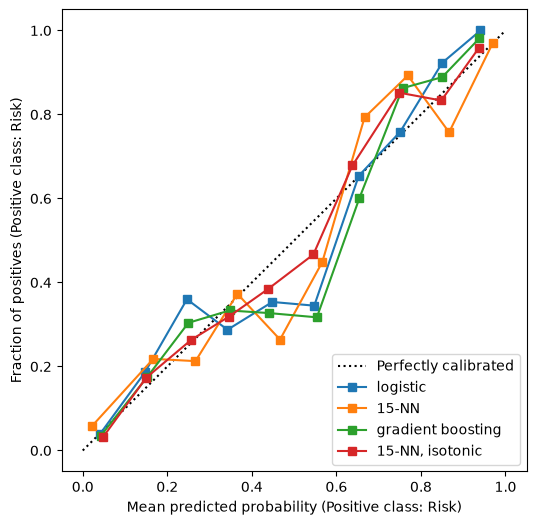

In [40]:
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, log_loss
calibration_models = {'logistic': clone(pipeline_log).fit(X_train, y_train),
                      '15-NN': clone(pipeline_nn).fit(X_train, y_train),
                      'gradient boosting': searches['grid'].best_estimator_}
calibration_models['15-NN, isotonic'] = CalibratedClassifierCV(clone(pipeline_nn), method='isotonic', cv=5).fit(X_train, y_train)
calibration_models['gradient boosting, sigmoid'] = CalibratedClassifierCV(clone(searches['grid'].best_estimator_), method='sigmoid',
                                                                          cv=5).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(6, 6))
for name in ['logistic', '15-NN', 'gradient boosting', '15-NN, isotonic']:
  CalibrationDisplay.from_estimator(calibration_models[name], X_test, y_test, pos_label='Risk', n_bins=10, name=name, ax=ax)
pl.DataFrame([{'model': name, 'Brier score': brier_score_loss(y_test, model.predict_proba(X_test)[:, 1], pos_label='Risk'),
               'log loss': log_loss(y_test, model.predict_proba(X_test)),
               'gain (Bayes decision)': cost_scorer_from_proba(model, X_test, y_test, LoanAmount=LoanAmount_test)}
              for name, model in calibration_models.items()])

**Conclusion** The logistic regression and the gradient boosting are well calibrated (Brier scores $0.135$ and $0.136$, log losses $0.41$ and $0.42$). The $15$-NN produces only the probabilities $0, 1/15, \dots, 1$, with a much larger log loss ($0.60$); its isotonic calibration improves it ($0.43$) and its gain from $92.1$ to $94.6$. The calibration of the gradient boosting does not improve its gain ($97.4$ to $96.3$): a well calibrated model gains nothing, and the differences of a few points are within the noise of the test set.

---

### The geometry of cost-sensitive decisions (★★)

Each threshold on the probability of `Risk` gives a point of the ROC curve: its false positive rate (good loans refused) and its true positive rate (defaulting loans refused). If the costs did not depend on the amount, the regret of a threshold would be $\pi_{\text{No Risk}}\, c_{FP}\, \text{FPR} + \pi_{\text{Risk}}\, c_{FN}\, (1 - \text{TPR})$: the thresholds with the same regret lie on a line of slope $\pi_{\text{No Risk}} c_{FP} / (\pi_{\text{Risk}} c_{FN})$ (an *iso-cost line*), and the best threshold is where such a line touches the ROC curve.

**Question** Plot the ROC curve of the logistic regression on the test set with the iso-cost line for a loan of average amount, and the points of `predict` (threshold $1/2$), of the tuned threshold and of the Bayes rule.

**Answer**

decision,FPR,TPR
str,f64,f64
"""predict (threshold 1/2)""",0.112613,0.625749
"""tuned threshold""",0.037538,0.5
"""Bayes rule""",0.037538,0.5


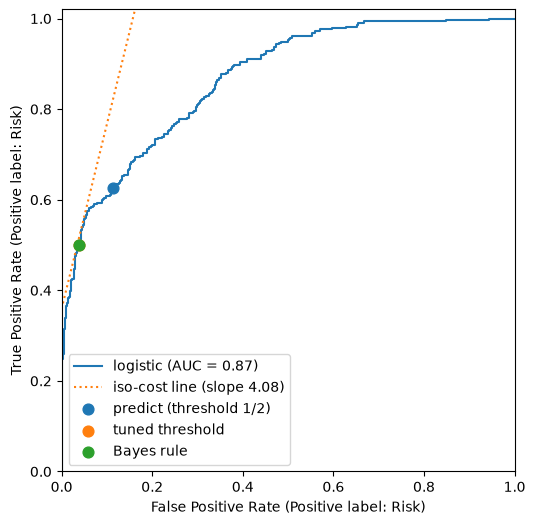

In [41]:
from sklearn.metrics import roc_curve, RocCurveDisplay
model = clone(pipeline_log).fit(X_train, y_train)
proba_test = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_test, pos_label='Risk')
mean_costs = compute_costs(LoanAmount_test.mean())
slope = (real_prop['No Risk'] * (mean_costs['No Risk_Risk'] - mean_costs['No Risk_No Risk'])
         / (real_prop['Risk'] * (mean_costs['Risk_No Risk'] - mean_costs['Risk_Risk'])))
best = np.argmax(tpr - slope * fpr)
def roc_point(y_pred):
  y_pred = pl.Series(y_pred)
  return (((y_pred == 'Risk') & (y_test == 'No Risk')).sum() / (y_test == 'No Risk').sum(),
          ((y_pred == 'Risk') & (y_test == 'Risk')).sum() / (y_test == 'Risk').sum())
tuned = TunedThresholdClassifierCV(clone(pipeline_log), scoring=cost_scorer, cv=5).fit(X_train, y_train, LoanAmount=LoanAmount_train)
points = {'predict (threshold 1/2)': roc_point(model.predict(X_test)), 'tuned threshold': roc_point(tuned.predict(X_test)),
          'Bayes rule': roc_point(apm_credit.cost_predict(model, X_test, LoanAmount_test))}
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, proba_test, pos_label='Risk', name='logistic', ax=ax)
line = np.linspace(0, 1, 2)
ax.plot(line, tpr[best] + slope * (line - fpr[best]), ':', label=f'iso-cost line (slope {slope:.2f})')
for name, (x, y_) in points.items():
  ax.scatter(x, y_, s=60, label=name, zorder=3)
ax.set(xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
pl.DataFrame([{'decision': name, 'FPR': p[0], 'TPR': p[1]} for name, p in points.items()])

**Conclusion** The usual prediction (threshold $1/2$) refuses $11\%$ of the good loans and $63\%$ of the defaulting ones. The Bayes rule and the tuned threshold, which coincide, are further down the ROC curve: they refuse only $3.8\%$ of the good loans and $50\%$ of the defaulting ones, near the point where the iso-cost line touches the curve. The ROC curve does not depend on the costs nor on the proportions: only the slope of the iso-cost lines, and thus the chosen point, does.

---

### Pruning and other samplers in Optuna (★★)

Successive halving can also be used *inside* a Bayesian optimization: each trial reports intermediate scores (here after $20, 40, \dots, 100$ boosting iterations, thanks to `warm_start`), and a *pruner* stops the unpromising trials early (Hyperband runs several successive halving brackets). Optuna also offers other samplers, e.g. CMA-ES, an evolution strategy (the *evolutionary* approach of the lecture).

**Question** Run $40$ trials of TPE with a `HyperbandPruner` on the learning rate and the number of leaves, reporting the $3$-fold CV gain after $20, 40, \dots, 100$ iterations. How many trials are pruned, and how much time is saved compared with the $20$ unpruned trials of the core part? Run then $20$ trials with the `CmaEsSampler`.

**Answer**

In [42]:
def objective_pruned(trial):
  params = {'learning_rate': trial.suggest_float('learning_rate', 0.01, 1, log=True),
            'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 3, 63)}
  folds = list(cv3.split(X_train, y_train))
  models = [clone(pipeline_hgb).set_params(classifier__warm_start=True, **{f'classifier__{k}': v for k, v in params.items()})
            for _ in folds]
  for step, n_iter in enumerate(range(20, 101, 20)):
    gains = []
    for model, (train, valid) in zip(models, folds):
      model.set_params(classifier__max_iter=n_iter).fit(X_train[train], y_train[train])
      gains.append(cost_scorer_from_proba(model, X_train[valid], y_train[valid], LoanAmount=LoanAmount_train[valid]))
    trial.report(np.mean(gains), step)
    if trial.should_prune():
      raise optuna.TrialPruned()
  return np.mean(gains)

start = time.perf_counter()
study_pruned = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0),
                                   pruner=optuna.pruners.HyperbandPruner(min_resource=1, max_resource=5, reduction_factor=3))
study_pruned.optimize(objective_pruned, n_trials=40)
pruned_time = time.perf_counter() - start
states = [t.state.name for t in study_pruned.trials]
{'pruned trials': states.count('PRUNED'), 'complete trials': states.count('COMPLETE'), 'best CV gain': study_pruned.best_value,
 'time (s)': pruned_time, 'time of the 20 unpruned TPE trials (s)': timings['TPE (Optuna)']}

{'pruned trials': 24,
 'complete trials': 16,
 'best CV gain': 96.26218243305654,
 'time (s)': 135.8985959999991,
 'time of the 20 unpruned TPE trials (s)': 56.642823499998485}

In [43]:
start = time.perf_counter()
study_cma = optuna.create_study(direction='maximize', sampler=optuna.samplers.CmaEsSampler(seed=0))
study_cma.optimize(objective, n_trials=20)
{'CMA-ES best CV gain': study_cma.best_value, 'time (s)': time.perf_counter() - start, 'TPE best CV gain': study.best_value}

{'CMA-ES best CV gain': 96.2358980136122,
 'time (s)': 47.685105100004876,
 'TPE best CV gain': 96.16606033285613}

**Conclusion** The Hyperband pruner stops $24$ of the $40$ trials after a few boosting iterations, and reaches a similar best CV gain ($96.3$). It does not save time here: each intermediate report needs a $3$-fold CV, and on such a small dataset these evaluations cost as much as the training itself, so that the $40$ trials take longer than the $20$ unpruned ones. Pruning pays off when each trial is expensive (large data, deep networks) and the intermediate scores are cheap. CMA-ES reaches $96.2$ with $20$ trials, the same as TPE: with only two hyperparameters, all the strategies end up in the same region.

---

### AutoML frameworks and stacking (★★)

AutoML frameworks search over pipelines (models and hyperparameters) with a time budget. `FLAML` uses a cost-aware search; AutoGluon (heavier: on Colab, or locally in a separate environment, see the AutoGluon notebook of Lab 3) trains many models and *stacks* them. Stacking can also be done by hand: a final model learns how to combine the cross-validated predictions of several base models.

Our gain is not a standard metric, so we let the frameworks optimize the log loss (good probabilities), and take the Bayes decision on their probabilities.

**Question** Run FLAML with a time budget of $60$ seconds (log loss), and build a `StackingClassifier` of the logistic regression, the $15$-NN and the tuned gradient boosting. Compare the gains of their Bayes decisions with the ones of the core part. (Optional, on Colab or in a separate local environment: AutoGluon with `presets='medium_quality'` and `time_limit=120`.)

**Answer**

In [44]:
from flaml import AutoML
from sklearn.ensemble import StackingClassifier
from sklearn.preprocessing import OrdinalEncoder
import tempfile, contextlib
automl = AutoML()
with contextlib.chdir(tempfile.mkdtemp()):  # some learners (CatBoost) write their files in the working directory
  automl.fit(X_train.to_pandas(), y_train.to_pandas(), task='classification', metric='log_loss', time_budget=60,
             log_file_name='flaml.log', seed=0, verbose=0)
stacking = StackingClassifier(estimators=[('logistic', clone(pipeline_log)), ('15-NN', clone(pipeline_nn)),
                                          ('boosting', clone(searches['grid'].best_estimator_))],
                              final_estimator=LogisticRegression(), cv=5).fit(X_train, y_train)
print('FLAML selected:', automl.best_estimator, automl.best_config)
pl.DataFrame([{'model': 'FLAML', 'gain': -cost_metric(y_test, apm_credit.cost_predict_from_proba(
                  automl.predict_proba(X_test.to_pandas()), LoanAmount_test), LoanAmount_test)},
              {'model': 'stacking', 'gain': cost_scorer_from_proba(stacking, X_test, y_test, LoanAmount=LoanAmount_test)},
              {'model': 'grid search (core)', 'gain': cost_scorer_from_proba(searches['grid'].best_estimator_, X_test, y_test,
                                                                              LoanAmount=LoanAmount_test)}])

FLAML selected: catboost {'early_stopping_rounds': 10, 'learning_rate': np.float64(0.09999999999999996), 'n_estimators': 8192}


model,gain
str,f64
"""FLAML""",97.630409
"""stacking""",95.654891
"""grid search (core)""",97.441249


**Conclusion** In $60$ seconds, FLAML selects a CatBoost model, whose Bayes decision reaches a test gain of $97.6$, the same level as our tuned gradient boosting ($97.4$). The stacking of the logistic regression, the $15$-NN and the gradient boosting does not improve on its best member here ($95.7$). AutoML is a good way to obtain quickly a strong baseline; our hand-made pipeline, with a model adapted to the problem, is as good.

---

### A tabular foundation model: AutoML without search (★★)

*Meta-learning* goes one step further than AutoML: a model pretrained on millions of synthetic datasets (here TabICL v2, Lecture 3) predicts the labels of the test set *in context*, from the training set, without any training nor hyperparameter search. It runs on a CPU for a dataset of this size, but is much faster on a GPU.

**Question** Compute the gain of the Bayes decision with the probabilities of `TabICLClassifier`, and compare it with the tuned gradient boosting.

**Answer**

In [45]:
from tabicl import TabICLClassifier
tabicl_pipeline = Pipeline([('encoder', ColumnTransformer([('cat', OrdinalEncoder(), categorical_features)], remainder='passthrough')),
                            ('classifier', TabICLClassifier(random_state=0))]).set_output(transform='pandas')
start = time.perf_counter()
tabicl_pipeline.fit(X_train.to_pandas(), y_train.to_pandas())
proba = tabicl_pipeline.predict_proba(X_test.to_pandas())
{'TabICL gain': -cost_metric(y_test, apm_credit.cost_predict_from_proba(proba, LoanAmount_test), LoanAmount_test),
 'time (s)': time.perf_counter() - start,
 'tuned gradient boosting gain': cost_scorer_from_proba(searches['grid'].best_estimator_, X_test, y_test, LoanAmount=LoanAmount_test)}

{'TabICL gain': 97.82347103990219,
 'time (s)': 121.42730479999591,
 'tuned gradient boosting gain': 97.44124876373381}

**Conclusion** Without any training nor tuning, TabICL reaches a test gain of $97.8$, as good as the tuned gradient boosting ($97.4$), in about two minutes on a CPU. Tabular foundation models are a strong default for small datasets (Lecture 3); their cost is at prediction time.

---

### STL decomposition (★)

STL (Seasonal-Trend decomposition using LOESS) splits a series into a trend, a seasonal component and a remainder with local regressions. The *strength* of the seasonality, $\max(0, 1 - \text{Var}(R)/\text{Var}(S+R))$, measures how much of the detrended variability is seasonal.

**Question** Decompose the monthly CO$_2$ series with `statsmodels`' `STL` (period $12$), plot the components and compute the strengths of the trend and of the seasonality.

**Answer**

{'trend strength': np.float64(0.9997366309237603),
 'seasonal strength': np.float64(0.9816238760557594)}

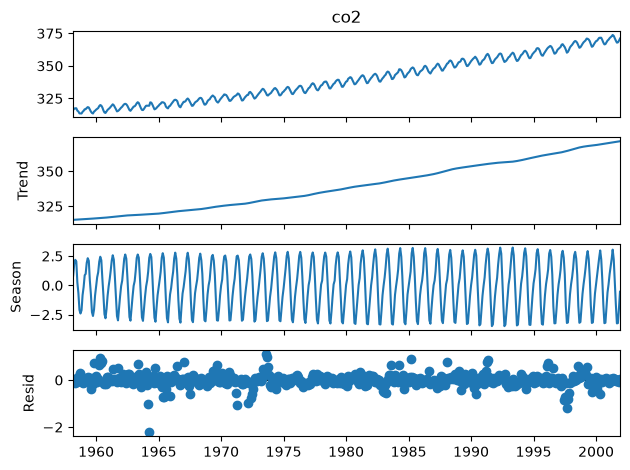

In [46]:
from statsmodels.tsa.seasonal import STL
co2_series = co2.to_pandas().set_index('date')['co2'].asfreq('MS')
stl = STL(co2_series, period=12, robust=True).fit()
stl.plot()
plt.show()
R, S, T = stl.resid, stl.seasonal, stl.trend
{'trend strength': max(0, 1 - R.var() / (T + R).var()), 'seasonal strength': max(0, 1 - R.var() / (S + R).var())}

**Conclusion** The trend strength ($0.9998$) and the seasonal strength ($0.98$) are both very close to $1$: the CO$_2$ series is almost entirely made of a smooth trend and a stable yearly cycle, with a small remainder. This is why simple models (seasonal naive plus trend, ridge on Fourier terms) work so well on it.

---

### ARIMA models (★★)

The statistical approach models the dependence explicitly: a seasonal ARIMA $(p,d,q)\times(P,D,Q)_{12}$ differences the series ($d$ times, and $D$ times at lag $12$) and models the result as an ARMA process. Once fitted on the training period, the same model can be *applied* to new data without refitting, to forecast from each origin.

**Question** Fit a SARIMA$(1,1,1)\times(0,1,1)_{12}$ on the training period (the *airline model*). For each origin of the test period, forecast $12$ months ahead (with `results.apply` on the series up to the origin), and compare the MAE with the ridge regression of the core part.

**Answer**

In [47]:
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
train_series = co2_series[co2_series.index.year < 1991]
sarima = SARIMAX(train_series, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
forecasts = {}
origins = co2_series.index[(co2_series.index.year >= 1991) & (co2_series.index < co2_series.index[-H])]
for origin in origins:
  applied = sarima.apply(co2_series[:origin])
  forecasts[origin + pd.DateOffset(months=H)] = applied.forecast(H).iloc[-1]
forecasts = pd.Series(forecasts)
target = co2_series[forecasts.index]
{'SARIMA MAE (12 months ahead)': np.mean(np.abs(forecasts - target)), 'ridge MAE (core part)': test_mae['ridge'],
 'test months': len(forecasts)}

{'SARIMA MAE (12 months ahead)': np.float64(0.6678038332595306),
 'ridge MAE (core part)': 0.6615587633291853,
 'test months': 120}

**Conclusion** With parameters frozen before the first forecast origin and observations updated through each origin, SARIMA gives an MAE of $0.668$ ppm over 120 months. Ridge on levels gives $0.662$ ppm on the same targets.

---

### Prediction intervals (★★)

A forecast is more useful with its uncertainty. Two simple ways to get an $80\%$ interval: fit two quantile regressions (levels $0.1$ and $0.9$, with the *pinball* loss), or use *split conformal prediction*: compute the absolute residuals of a model on a calibration period that follows its training period, and add $\pm$ their $80\%$ quantile to the forecasts.

**Question** On the seasonal difference target, build $80\%$ intervals with two quantile gradient boostings, and with split conformal prediction around the ridge regression (calibration period: 1986–1990, after a training period ending in 1984). Compare their coverage and their average width on the test period.

**Answer**

In [48]:
quantile_models = {alpha: HistGradientBoostingRegressor(loss='quantile', quantile=alpha, random_state=0).fit(train_ts[features], target_diff)
                   for alpha in (0.1, 0.9)}
low = test_ts['lag_12'].to_numpy() + quantile_models[0.1].predict(test_ts[features])
high = test_ts['lag_12'].to_numpy() + quantile_models[0.9].predict(test_ts[features])
fit_part = train_ts.filter(pl.col('date').dt.year() < 1985)
calibration = train_ts.filter(pl.col('date').dt.year() >= 1986)
ridge = Pipeline([('scaler', StandardScaler()), ('model', RidgeCV(alphas=np.logspace(-3, 3, 13)))]).fit(
    fit_part[features], fit_part['co2'] - fit_part['lag_12'])
scores = np.sort(np.abs(calibration['co2'] - calibration['lag_12'] - ridge.predict(calibration[features])))
rank = int(np.ceil(0.8 * (len(scores) + 1)))
q = scores[rank - 1] if rank <= len(scores) else np.inf
center = test_ts['lag_12'].to_numpy() + ridge.predict(test_ts[features])
truth = test_ts['co2'].to_numpy()
pl.DataFrame([{'interval': 'quantile boosting', 'coverage': np.mean((truth >= low) & (truth <= high)), 'average width': np.mean(high - low)},
              {'interval': 'split conformal (ridge)', 'coverage': np.mean(np.abs(truth - center) <= q), 'average width': 2 * q}])

interval,coverage,average width
str,f64,f64
"""quantile boosting""",0.475,0.841721
"""split conformal (ridge)""",0.791667,1.843146


**Conclusion** The quantile boosting intervals have mean width $0.84$ ppm and cover $47.5\%$ of test values. The split-conformal ridge intervals have mean width $1.84$ ppm and cover $79.2\%$. The finite-sample rank correction assumes exchangeable scores for its coverage guarantee. Temporal dependence and changes in growth rate can affect coverage here.

---

### A small neural forecaster (★★)

The deep learning approach of the lecture learns the forecast function with a neural network. On such a small series, a small multilayer perceptron is enough to see the main points: a neural network does not extrapolate either, so its inputs *and* its target must be stationary; the inputs must be standardized; and the training must be stopped before it overfits.

**Question** Build stationary inputs: the differences `lag_k - lag_12` for $k = 13, \dots, 24$ and the Fourier terms. Train with PyTorch a perceptron with one hidden layer of $32$ units on these standardized inputs, predicting the standardized seasonal difference, with Adam and early stopping on the last $3$ years of the training period. Compare its test MAE with the ridge regression. (What happens with the raw `features`, which contain the level of the series?)

**Answer**

In [49]:
import torch
torch.manual_seed(0)
stationary = ['sin_1', 'cos_1', 'sin_2', 'cos_2'] + [f'dlag_{lag}' for lag in range(H + 1, H + 13)]
def add_stationary(part):
  return part.with_columns(*[(pl.col(f'lag_{lag}') - pl.col('lag_12')).alias(f'dlag_{lag}') for lag in range(H + 1, H + 13)])
train_st, test_st = add_stationary(train_ts), add_stationary(test_ts)
fit_part, valid_part = train_st.filter(pl.col('date').dt.year() < 1988), train_st.filter(pl.col('date').dt.year() >= 1989)
scaler_x = StandardScaler().fit(fit_part[stationary])
d_fit = (fit_part['co2'] - fit_part['lag_12']).to_numpy()
mu, sd = d_fit.mean(), d_fit.std()
def tensors(part):
  return (torch.tensor(scaler_x.transform(part[stationary]), dtype=torch.float32),
          torch.tensor(((part['co2'] - part['lag_12']).to_numpy() - mu) / sd, dtype=torch.float32))
(xf, yf), (xv, yv), (xt, _) = tensors(fit_part), tensors(valid_part), tensors(test_st)
net = torch.nn.Sequential(torch.nn.Linear(len(stationary), 32), torch.nn.ReLU(), torch.nn.Linear(32, 1))
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
best_loss, best_state, history = np.inf, None, []
for epoch in range(2000):
  optimizer.zero_grad()
  loss = torch.mean((net(xf).squeeze() - yf) ** 2)
  loss.backward()
  optimizer.step()
  with torch.no_grad():
    valid_loss = torch.mean((net(xv).squeeze() - yv) ** 2).item()
  history.append({'epoch': epoch, 'training loss': loss.item(), 'validation loss': valid_loss})
  if valid_loss < best_loss:
    best_loss, best_state, best_epoch = valid_loss, {k: v.clone() for k, v in net.state_dict().items()}, epoch
net.load_state_dict(best_state)
with torch.no_grad():
  forecast = test_ts['lag_12'].to_numpy() + mu + sd * net(xt).squeeze().numpy()
print('best epoch:', best_epoch)
{'MLP test MAE': mean_absolute_error(test_ts['co2'], forecast), 'ridge (seasonal difference) test MAE': test_mae['ridge (seasonal difference)']}

best epoch: 5


{'MLP test MAE': 0.6453761339039616,
 'ridge (seasonal difference) test MAE': 0.6222454195551185}

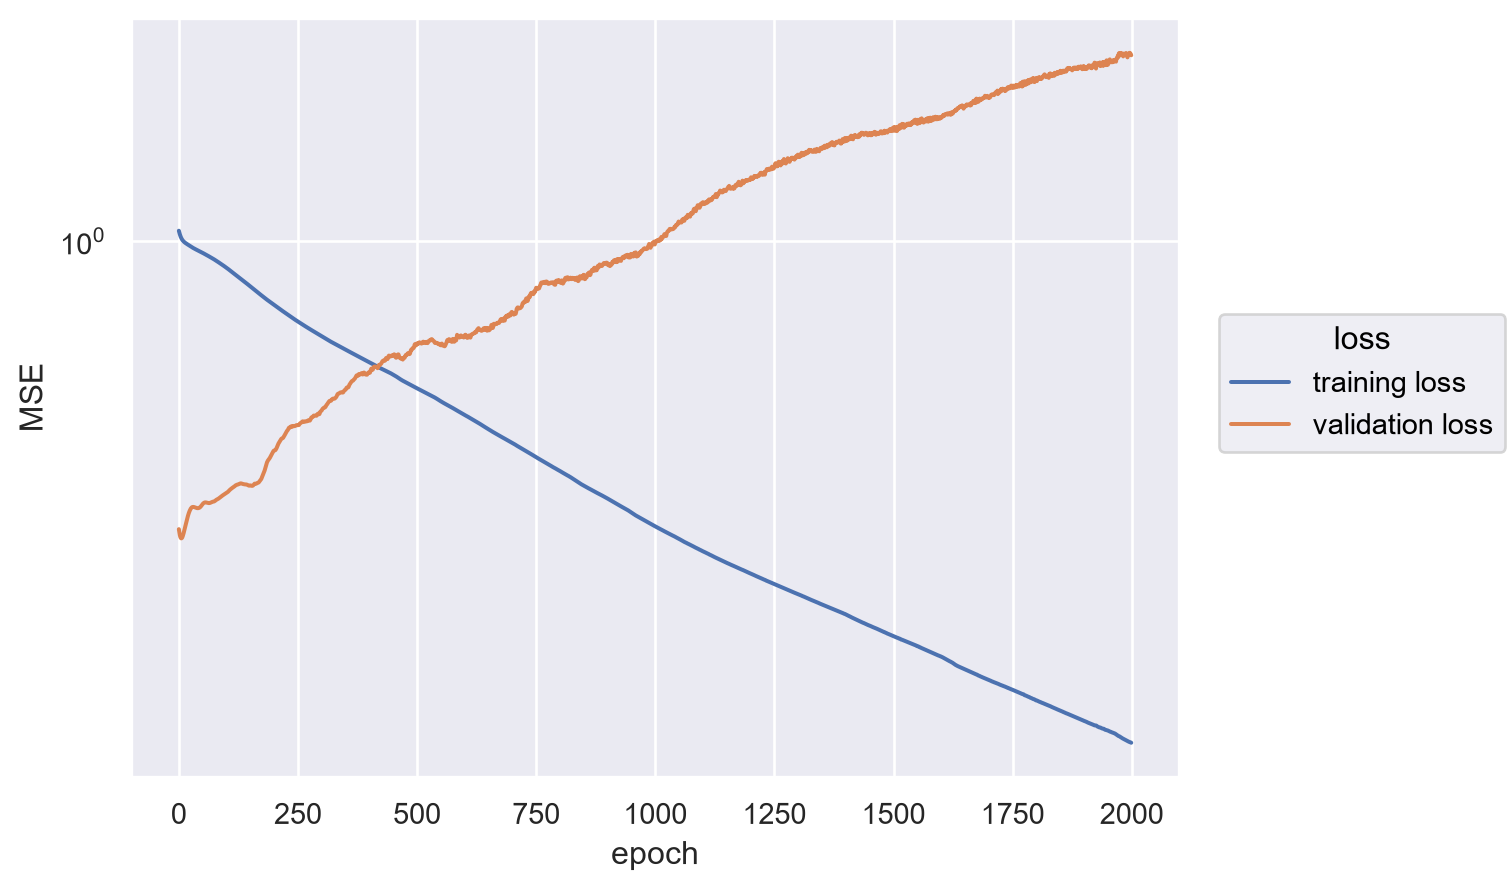

In [50]:
so.Plot(pl.DataFrame(history).unpivot(index='epoch', variable_name='loss', value_name='MSE'), x='epoch', y='MSE', color='loss').add(so.Line()).scale(y='log')

**Conclusion** Validation loss is smallest at epoch index $5$ (after six updates). The selected network has test MAE $0.645$ ppm, compared with $0.622$ for ridge on the seasonal difference. Early stopping uses only the chronological validation block.

---

### Zero-shot forecasting with a foundation model (★★★)

Time series foundation models are pretrained on very many (real and synthetic) series and forecast a new series *zero-shot*, from its past only. Chronos-2 (Amazon, 2025) is one of them; it outputs quantiles. It runs on a CPU for a few series (a GPU is faster).

**Question** For each January of the test period (1992 to 2001), give Chronos-2 the series up to the previous December and forecast the next $12$ months. Compare the MAE of the $12$-months-ahead forecasts (the last month of each forecast) with the ridge regression on the same months, and the coverage of its $80\%$ interval.

**Answer**

In [51]:
from chronos import Chronos2Pipeline
import pandas as pd
import time
chronos_pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
contexts = pd.concat([co2_series[co2_series.index < f'{year}-01-01'].rename('target').reset_index()
                      .rename(columns={'date': 'timestamp'}).assign(item_id=str(year)) for year in range(1992, 2002)])
start = time.perf_counter()
chronos_forecast = chronos_pipeline.predict_df(contexts, prediction_length=12, quantile_levels=[0.1, 0.5, 0.9])
chronos_time = time.perf_counter() - start
last = chronos_forecast.groupby('item_id').tail(1).set_index('timestamp')
truth = co2_series[last.index]
ridge_last = test_ts.filter(pl.col('date').dt.date().is_in(list(last.index.date)))  # compare dates: the time units differ between pandas versions
# models_ts['ridge'] was last fitted on the seasonal difference (core part): add lag_12 back
{'Chronos-2 MAE (12 months ahead)': np.mean(np.abs(last['0.5'] - truth)),
 'ridge (seasonal difference) MAE on the same months': mean_absolute_error(
     ridge_last['co2'], ridge_last['lag_12'].to_numpy() + models_ts['ridge'].predict(ridge_last[features])),
 'coverage of the 80% interval': np.mean((truth >= last['0.1']) & (truth <= last['0.9'])), 'time (s)': chronos_time}

{'Chronos-2 MAE (12 months ahead)': np.float64(0.6669268798828171),
 'ridge (seasonal difference) MAE on the same months': 0.48175279072062266,
 'coverage of the 80% interval': np.float64(0.7),
 'time (s)': 4.23415199998999}

**Conclusion** Over ten December targets, the zero-shot Chronos-2 forecast has 12-month MAE $0.667$ ppm. Ridge on seasonal differences gives $0.482$ ppm on the same months. The nominal $80\%$ Chronos interval contains seven of the ten observations. This comparison concerns one series and ten forecasts.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.